Loading Indian Pines (.mat)...

========== ABLATION RUN 1/10 | seed=1 ==========

========== ABLATION RUN 2/10 | seed=2 ==========

========== ABLATION RUN 3/10 | seed=3 ==========

========== ABLATION RUN 4/10 | seed=4 ==========

========== ABLATION RUN 5/10 | seed=5 ==========

========== ABLATION RUN 6/10 | seed=6 ==========

========== ABLATION RUN 7/10 | seed=7 ==========

========== ABLATION RUN 8/10 | seed=8 ==========

========== ABLATION RUN 9/10 | seed=9 ==========

========== ABLATION RUN 10/10 | seed=10 ==========

Saved ablation runs -> IP_Ablation_Results.csv
Saved ablation boxplot figure -> Fig_IP_Ablation_Boxplot.png


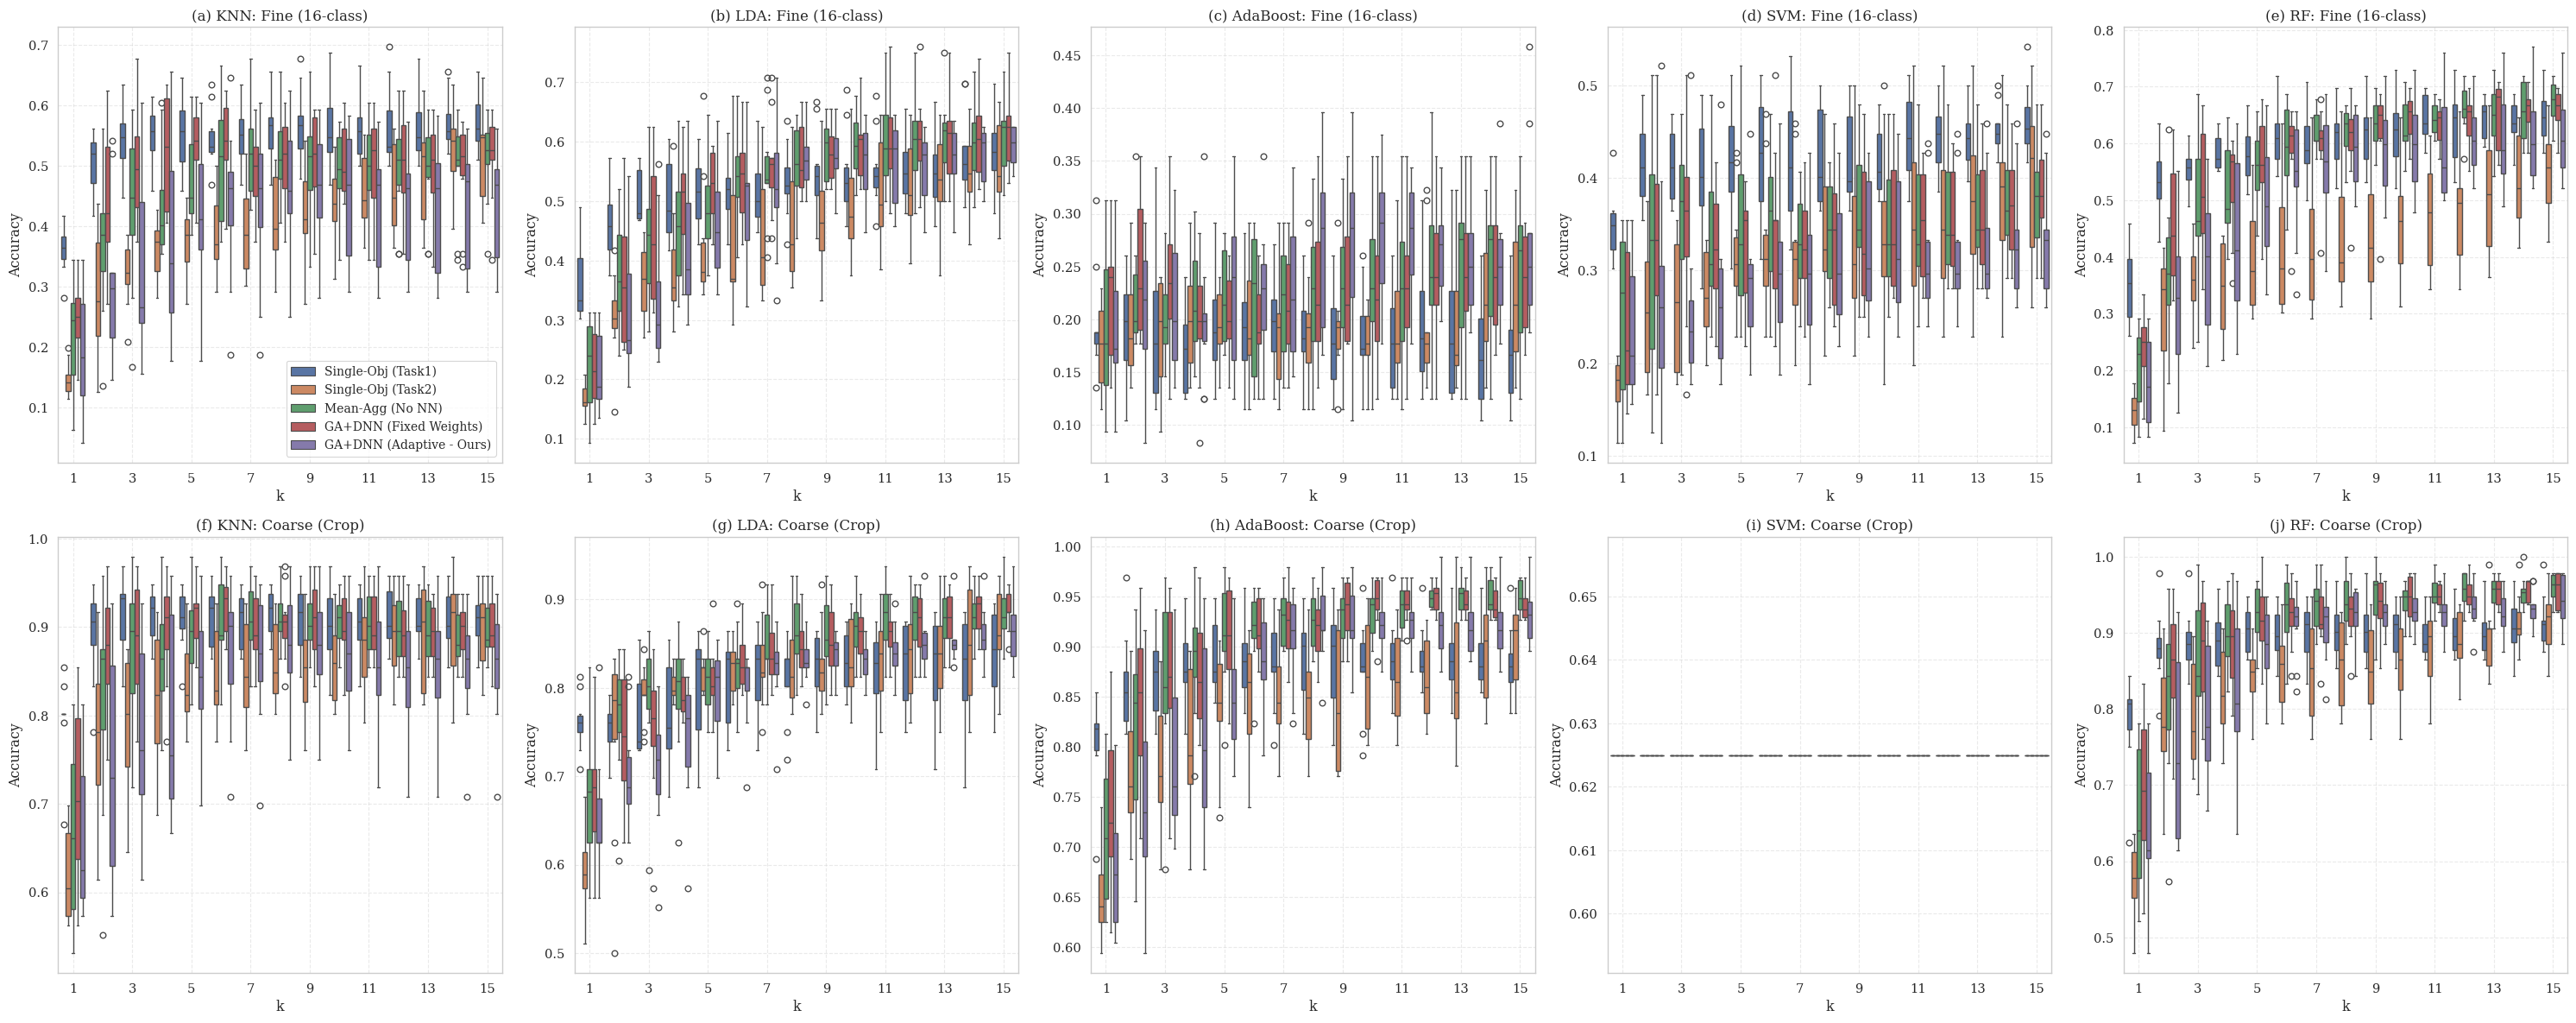

In [1]:
# ==============================================================
# 第三个实验 (Indian Pines - Dual Task)
# 消融实验专属纯净代码 (Ablation Study)
# 仅评估模型内部组件，并自动生成箱型图 (Boxplot)
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import scipy.io as sio

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize

# --- Classifiers ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.svm import SVC

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# A. Utilities: Load .mat, labels, subsample
# ==============================================================
def _load_mat_first_var(mat_path: str):
    d = sio.loadmat(mat_path)
    keys = [k for k in d.keys() if not k.startswith("__")]
    if len(keys) == 0: raise ValueError(f"No data variable found in {mat_path}")
    return d[keys[0]]

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    rng = np.random.default_rng(seed)
    selected = []
    classes = np.unique(y)
    for c in classes:
        idx = np.where(y == c)[0]
        if len(idx) >= n_per_class:
            chosen = rng.choice(idx, n_per_class, replace=False)
        else:
            chosen = idx if keep_all_if_less else rng.choice(idx, n_per_class, replace=True)
        selected.append(chosen)
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return X[selected], y[selected], selected

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = np.array([1, 2, 3, 4, 8, 9, 10, 11, 12, 13])
    return np.isin(y_fine, crop_classes).astype(int)

# ==============================================================
# 1. Fitness Functions
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_task1(mask, xt, y_task1, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi = mutual_info_classif(xt[:, sel], y_task1, random_state=42)
    return -float(np.mean(mi)) + _size_penalty(len(sel), xt.shape[1], lam)

def calc_redundancy(mask, xt, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt.shape[1], lam)
    Xs = xt[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / (Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = len(sel)
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt.shape[1], lam)

def calc_mi_task2(mask, xt, y_task2, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi = mutual_info_classif(xt[:, sel], y_task2, random_state=42)
    return float(np.mean(mi)) + _size_penalty(len(sel), xt.shape[1], lam)

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj(xtrain, ytrain, y_task2, mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = xtrain.shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)

    def get_fitness(ind):
        if mode == 'task1': return calc_mi_task1(ind, xtrain, ytrain)
        elif mode == 'redundancy': return calc_redundancy(ind, xtrain)
        elif mode == 'task2': return calc_mi_task2(ind, xtrain, y_task2)
        return 0

    fit = np.array([get_fitness(X[i]) for i in range(N)])
    
    for _ in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()

        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)

        for i in range(Nc):
            P1, P2 = X[roulette_wheel(prob)], X[roulette_wheel(prob)]
            idx = 1 if dim <= 2 else np.random.randint(1, dim - 1)
            child1, child2 = np.concatenate((P1[:idx], P2[idx:])), np.concatenate((P2[:idx], P1[idx:]))
            for d in range(dim):
                if np.random.rand() < MR: child1[d] = 1 - child1[d]
                if np.random.rand() < MR: child2[d] = 1 - child2[d]
            x1[i], x2[i] = child1, child2

        Xnew = np.vstack((x1, x2))
        Fnew = np.array([get_fitness(Xnew[i]) for i in range(Xnew.shape[0])])
        XX, FF = np.vstack((X, Xnew)), np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]

    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Ablation Variants (SoftMaskNet)
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

# 变体 1: GA+DNN (Adaptive - Ours)
def train_softmask_dnn_adaptive(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    X_list = []
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)

    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            target = (current_w[0] * m1 + current_w[1] * m2 + current_w[2] * m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# 变体 2: GA+DNN (Fixed Weights)
def train_softmask_dnn_fixed(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    X_list = []
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)

    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) # 无动态权重
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            target = (fixed_w[0] * m1 + fixed_w[1] * m2 + fixed_w[2] * m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. One-run Ablation Benchmark
# ==============================================================
def run_ablation_one_run(features, task1_labels, task2_labels, seed_for_split=42):
    y_task1 = np.asarray(task1_labels)
    y_task2 = np.asarray(task2_labels)
    feat = np.asarray(features)

    xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
        feat, y_task1, y_task2, test_size=0.3, stratify=y_task1, random_state=seed_for_split
    )
    n_features = xtrain.shape[1]
    opts = {'N': 50, 'T': 50}

    # 训练三个独立的 GA 种群
    pop1 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'task1', opts))
    pop2 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'redundancy', opts))
    pop3 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'task2', opts))

    # 计算消融变体得分
    scores_single_t1 = pop1.mean(0)
    scores_single_t2 = pop3.mean(0)
    scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
    scores_dnn_fixed = train_softmask_dnn_fixed(pop1, pop2, pop3, n_features)
    scores_dnn_adapt = train_softmask_dnn_adaptive(pop1, pop2, pop3, n_features)

    classifiers = {
        "KNN": KNeighborsClassifier(3),
        "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=seed_for_split),
        "SVM": SVC(kernel='linear', random_state=seed_for_split),
        "RF": RandomForestClassifier(n_estimators=50, random_state=seed_for_split)
    }

    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        if len(idx) == 0: idx = np.array([0])
        return idx

    results = []
    for k in range(1, 16):
        methods = {
            "Single-Obj (Task1)": get_top_k(scores_single_t1, k),
            "Single-Obj (Task2)": get_top_k(scores_single_t2, k),
            "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
            "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
            "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
        }

        for m_name, indices in methods.items():
            if len(indices) == 0: continue
            X_tr_sel, X_te_sel = xtrain[:, indices], xtest[:, indices]

            for clf_name, clf in classifiers.items():
                # Evaluate Task 1 (Fine)
                clf.fit(X_tr_sel, ytrain)
                results.append({
                    "Method": m_name, "Num_Features": k,
                    "Task": "Predict_Task1_Fine", "Classifier": clf_name, "Value": clf.score(X_te_sel, ytest)
                })

                # Evaluate Task 2 (Crop)
                clf.fit(X_tr_sel, y2_tr)
                results.append({
                    "Method": m_name, "Num_Features": k,
                    "Task": "Predict_Task2_Crop", "Classifier": clf_name, "Value": clf.score(X_te_sel, y2_te)
                })

    return pd.DataFrame(results)

# ==============================================================
# 5. Multi-run wrapper & Ablation BOXplots
# ==============================================================
def run_ablation_and_save_boxplots(X, y_task1, y_task2, seeds, out_csv="IP_Ablation_Results.csv", out_plot="Fig_IP_Ablation_Boxplot.png"):
    all_runs = []
    for run_id, seed in enumerate(seeds, start=1):
        print(f"\n========== ABLATION RUN {run_id}/{len(seeds)} | seed={seed} ==========")
        set_seed(seed)
        df_res = run_ablation_one_run(X, y_task1, y_task2, seed_for_split=seed)
        df_res["Run"], df_res["Seed"] = run_id, seed
        all_runs.append(df_res)

    df_all = pd.concat(all_runs, ignore_index=True)
    df_all.to_csv(out_csv, index=False)
    print(f"\nSaved ablation runs -> {out_csv}")

    # ---- 绘制 Ablation Boxplot ----
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.rcParams['font.family'] = 'serif'

    classifiers = ["KNN", "LDA", "AdaBoost", "SVM", "RF"]
    tasks = ["Predict_Task1_Fine", "Predict_Task2_Crop"]
    method_order = [
        "Single-Obj (Task1)", "Single-Obj (Task2)", 
        "Mean-Agg (No NN)", "GA+DNN (Fixed Weights)", "GA+DNN (Adaptive - Ours)"
    ]

    fig, axes = plt.subplots(2, 5, figsize=(30, 12))
    axes = axes.flatten()

    plot_idx = 0
    for task in tasks:
        for clf in classifiers:
            ax = axes[plot_idx]
            sub = df_all[(df_all["Task"] == task) & (df_all["Classifier"] == clf)].copy()
            if sub.empty:
                ax.set_axis_off()
                plot_idx += 1
                continue

            sns.boxplot(
                data=sub, x="Num_Features", y="Value",
                hue="Method", hue_order=method_order, ax=ax
            )

            title = f"({chr(97+plot_idx)}) {clf}: Fine (16-class)" if task == "Predict_Task1_Fine" else f"({chr(97+plot_idx)}) {clf}: Coarse (Crop)"
            ax.set_title(title, fontsize=12)
            ax.set_ylabel("Accuracy")
            ax.set_xlabel("k")
            ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
            ax.grid(True, linestyle="--", alpha=0.4)

            if plot_idx == 0:
                ax.legend(loc="lower right", frameon=True, fontsize=10, ncol=1)
            elif ax.get_legend():
                ax.get_legend().remove()

            plot_idx += 1

    plt.tight_layout()
    plt.savefig(out_plot, dpi=300, bbox_inches="tight")
    print(f"Saved ablation boxplot figure -> {out_plot}")

# ==============================================================
# 6. Main Entry Point
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True
    SEEDS = list(range(1, 11)) 

    try:
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ablation_and_save_boxplots(X, y_fine, y_crop, seeds=SEEDS)

    except Exception as e:
        print(f"Error: {e}")
        print("Running with Mock Data...")
        set_seed(42)
        X = np.random.rand(500, 200)
        y_fine = np.random.randint(1, 17, 500)
        y_crop = make_crop_label_from_indian_pines(y_fine)
        X = normalize(X + 1e-8, norm="l1", axis=1)
        
        run_ablation_and_save_boxplots(X, y_fine, y_crop, seeds=list(range(1, 3)))

In [5]:
import pandas as pd
import numpy as np

# 统一的方法排序，与论文表格的列顺序保持一致
METHOD_ORDER = [
    "Single-Obj (Task1)", 
    "Single-Obj (Task2)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

def load_and_prep_data(csv_path="IP_Ablation_Results.csv"):
    try:
        df = pd.read_csv(csv_path)
        
        # 【核心修改】：直接过滤掉其他分类器，只保留 LDA
        if "Classifier" in df.columns:
            df = df[df["Classifier"] == "LDA"]
        elif "Model" in df.columns: # 兼容不同的列名命名
            df = df[df["Model"] == "LDA"]
            
        if df.empty:
            print("警告：未能找到 LDA 分类器的数据，请检查 CSV 文件是否包含 LDA 模型的结果！")
            
        return df
    except FileNotFoundError:
        print(f"找不到文件 {csv_path}，请确保路径正确。")
        return None

def generate_tables(df):
    """
    根据过滤后的 DataFrame 生成两个双任务的透视表，并导出为 CSV 方便贴入 Excel
    """
    # ==========================================
    # 任务 1: Task 1 - Fine-grained (16-Class)
    # ==========================================
    df_task1 = df[df["Task"] == "Predict_Task1_Fine"]
    # 生成透视表：行是 Num_Features (K, 1-15)，列是 Method，值是 Value (Score) 的均值
    table_task1 = df_task1.pivot_table(index="Num_Features", columns="Method", values="Value", aggfunc="mean")
    
    # 调整列顺序
    valid_cols_t1 = [m for m in METHOD_ORDER if m in table_task1.columns]
    table_task1 = table_task1[valid_cols_t1]

    print("\n========== 表格 1: Task 1 (16-Class) Accuracy - 仅 LDA ==========")
    print(table_task1.round(4)) # 控制台打印保留 4 位小数
    
    # 导出为 CSV
    t1_csv_name = "Table_Ablation_IP_Task1_LDA.csv"
    table_task1.round(4).to_csv(t1_csv_name)
    print(f"-> 已保存至: {t1_csv_name}")


    # ==========================================
    # 任务 2: Task 2 - Coarse (Crop/Non-Crop)
    # ==========================================
    df_task2 = df[df["Task"] == "Predict_Task2_Crop"]
    # 生成透视表：行是 Num_Features (K, 1-15)，列是 Method，值是 Value (Score) 的均值
    table_task2 = df_task2.pivot_table(index="Num_Features", columns="Method", values="Value", aggfunc="mean")
    
    # 调整列顺序
    valid_cols_t2 = [m for m in METHOD_ORDER if m in table_task2.columns]
    table_task2 = table_task2[valid_cols_t2]

    print("\n========== 表格 2: Task 2 (Crop/Non-Crop) Accuracy - 仅 LDA ==========")
    print(table_task2.round(4))
    
    # 导出为 CSV
    t2_csv_name = "Table_Ablation_IP_Task2_LDA.csv"
    table_task2.round(4).to_csv(t2_csv_name)
    print(f"-> 已保存至: {t2_csv_name}\n")


if __name__ == "__main__":
    print("加载消融实验数据 (仅限 LDA)...")
    df_results = load_and_prep_data("IP_Ablation_Results.csv")
    
    if df_results is not None:
        print("开始生成双任务平均值数据表...")
        generate_tables(df_results)
        print("所有表格生成完毕！你可以直接用 Excel 打开这两个新生成的 CSV 文件并复制进论文。")

加载消融实验数据 (仅限 LDA)...
开始生成双任务平均值数据表...

========== 表格 1: Task 1 (16-Class) Accuracy - 仅 LDA ==========
Method        Single-Obj (Task1)  Single-Obj (Task2)  Mean-Agg (No NN)  \
Num_Features                                                             
1                         0.3615              0.1656            0.2240   
2                         0.4635              0.3042            0.3729   
3                         0.5083              0.3646            0.4344   
4                         0.5062              0.3865            0.4542   
5                         0.5167              0.4250            0.4917   
6                         0.5229              0.4292            0.5354   
7                         0.5198              0.4375            0.5510   
8                         0.5333              0.4552            0.5667   
9                         0.5458              0.4781            0.5854   
10                        0.5458              0.4927            0.5958   
11        

In [9]:
# ==============================================================
# 第三个实验 (Indian Pines - Dual Task)
# 完整消融实验：包含双任务表格 (仅 LDA) + 掩码置信度分布图 (Histogram)
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import scipy.io as sio

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import matplotlib.pyplot as plt
import seaborn as sns

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = [
    "Single-Obj (Task1)", 
    "Single-Obj (Task2)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Plotting Function
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt):
    """
    绘制截断前 (Pre-Truncation) 的软掩码置信度分布图。
    这是用来证明 SoftMaskNet 能产生高置信度 (High Sharpness) 决策的核心图表！
    """
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.rcParams['font.family'] = 'serif'
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    
    # 绘制 Mean-Agg 的分布 (通常聚集在离散点)
    sns.histplot(scores_mean_agg, bins=20, color='gray', ax=axes[0], kde=True)
    axes[0].set_title("Mask Confidence: Mean-Agg (No NN)")
    axes[0].set_xlabel("Soft Mask Value")
    axes[0].set_ylabel("Frequency (Number of Features)")
    
    # 绘制 SoftMaskNet 的分布 (两极分化/双峰分布)
    sns.histplot(scores_dnn_adapt, bins=20, color='blue', ax=axes[1], kde=True)
    axes[1].set_title("Mask Confidence: GA+DNN (Adaptive - Ours)")
    axes[1].set_xlabel("Soft Mask Value")
    
    plt.suptitle("Feature Selection Confidence Distribution (Pre-Truncation)", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.savefig("Fig_Mask_Sharpness_Comparison.png", dpi=300, bbox_inches="tight")
    print("\n[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison.png")
    plt.close()

# ==============================================================
# A. Utilities: Load .mat, labels, subsample
# ==============================================================
def _load_mat_first_var(mat_path: str):
    d = sio.loadmat(mat_path)
    keys = [k for k in d.keys() if not k.startswith("__")]
    if len(keys) == 0: raise ValueError(f"No data variable found in {mat_path}")
    return d[keys[0]]

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    rng = np.random.default_rng(seed)
    selected = []
    classes = np.unique(y)
    for c in classes:
        idx = np.where(y == c)[0]
        if len(idx) >= n_per_class:
            chosen = rng.choice(idx, n_per_class, replace=False)
        else:
            chosen = idx if keep_all_if_less else rng.choice(idx, n_per_class, replace=True)
        selected.append(chosen)
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return X[selected], y[selected], selected

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = np.array([1, 2, 3, 4, 8, 9, 10, 11, 12, 13])
    return np.isin(y_fine, crop_classes).astype(int)

# ==============================================================
# 1. Fitness Functions
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_task1(mask, xt, y_task1, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi = mutual_info_classif(xt[:, sel], y_task1, random_state=42)
    return -float(np.mean(mi)) + _size_penalty(len(sel), xt.shape[1], lam)

def calc_redundancy(mask, xt, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt.shape[1], lam)
    Xs = xt[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / (Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = len(sel)
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt.shape[1], lam)

def calc_mi_task2(mask, xt, y_task2, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi = mutual_info_classif(xt[:, sel], y_task2, random_state=42)
    return float(np.mean(mi)) + _size_penalty(len(sel), xt.shape[1], lam)

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj(xtrain, ytrain, y_task2, mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = xtrain.shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)

    def get_fitness(ind):
        if mode == 'task1': return calc_mi_task1(ind, xtrain, ytrain)
        elif mode == 'redundancy': return calc_redundancy(ind, xtrain)
        elif mode == 'task2': return calc_mi_task2(ind, xtrain, y_task2)
        return 0

    fit = np.array([get_fitness(X[i]) for i in range(N)])
    
    for _ in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        for i in range(Nc):
            P1, P2 = X[roulette_wheel(prob)], X[roulette_wheel(prob)]
            idx = 1 if dim <= 2 else np.random.randint(1, dim - 1)
            child1, child2 = np.concatenate((P1[:idx], P2[idx:])), np.concatenate((P2[:idx], P1[idx:]))
            for d in range(dim):
                if np.random.rand() < MR: child1[d] = 1 - child1[d]
                if np.random.rand() < MR: child2[d] = 1 - child2[d]
            x1[i], x2[i] = child1, child2
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([get_fitness(Xnew[i]) for i in range(Xnew.shape[0])])
        XX, FF = np.vstack((X, Xnew)), np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Ablation Variants (SoftMaskNet)
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def train_softmask_dnn_adaptive(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    X_list = []
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)

    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            target = (current_w[0] * m1 + current_w[1] * m2 + current_w[2] * m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

def train_softmask_dnn_fixed(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    X_list = []
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)

    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) 
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            target = (fixed_w[0] * m1 + fixed_w[1] * m2 + fixed_w[2] * m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. Main Experiment & Table Generator
# ==============================================================
def run_ip_ablation_and_tables(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    print("="*70)
    print(f"Starting INDIAN PINES Ablation: {n_runs} Runs (LDA Only)")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        # Split data
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels, task2_labels, test_size=0.3, stratify=task1_labels, random_state=current_seed
        )
        n_features = xtrain.shape[1]
        opts = {'N': 50, 'T': 50}

        print("  Evolving Independent GA Populations...")
        pop1 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'task1', opts))
        pop2 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'redundancy', opts))
        pop3 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'task2', opts))

        print("  Computing Ablation Variants...")
        scores_single_t1 = pop1.mean(0)
        scores_single_t2 = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        scores_dnn_fixed = train_softmask_dnn_fixed(pop1, pop2, pop3, n_features)
        scores_dnn_adapt = train_softmask_dnn_adaptive(pop1, pop2, pop3, n_features)

        # 【核心功能】：仅在第一次 Run 时，画出锐度分布图
        if run_idx == 1:
            plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt)

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            if len(idx) == 0: idx = np.array([0])
            return idx

        # 仅使用 LDA
        clf = LinearDiscriminantAnalysis()

        for k in range(1, 16):
            methods = {
                "Single-Obj (Task1)": get_top_k(scores_single_t1, k),
                "Single-Obj (Task2)": get_top_k(scores_single_t2, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
            }

            for m_name, indices in methods.items():
                if len(indices) == 0: continue
                X_tr_sel, X_te_sel = xtrain[:, indices], xtest[:, indices]

                # Evaluate Task 1 (Fine)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Evaluate Task 2 (Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    df_results = pd.DataFrame(all_results)
    
    # -------------------------------------------------------------
    # Generate Tables
    # -------------------------------------------------------------
    print("\n\n" + "="*60)
    print("                 FINAL ABLATION TABLES (LDA Only)")
    print("="*60)
    
    # Task 1 Table
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc="mean")
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained (16-Class) Accuracy")
    print(table_t1.round(4))
    table_t1.round(4).to_csv("Table_Ablation_IP_Task1_LDA.csv")
    
    # Task 2 Table
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc="mean")
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy")
    print(table_t2.round(4))
    table_t2.round(4).to_csv("Table_Ablation_IP_Task2_LDA.csv")
    
    print("\n[+] 所有运行完毕！请查看生成的 CSV 表格和掩码直方图(Fig_Mask_Sharpness_Comparison.png)。")

# ==============================================================
# 5. Main Entry Point
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=10)

    except Exception as e:
        print(f"Error: {e}")
        print("Running with Mock Data...")
        set_seed(42)
        X = np.random.rand(500, 200)
        y_fine = np.random.randint(1, 17, 500)
        y_crop = make_crop_label_from_indian_pines(y_fine)
        X = normalize(X + 1e-8, norm="l1", axis=1)
        
        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES Ablation: 10 Runs (LDA Only)

>>> Run 1/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison.png

>>> Run 2/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 3/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 4/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 5/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 6/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 7/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 8/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 9/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 10/10...
  Evolving Independent GA P

In [10]:
# ==============================================================
# 第三个实验 (Indian Pines - Dual Task)
# 完整消融实验：包含双任务表格 (仅 LDA) + 掩码置信度分布图 + Mean±Std
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import scipy.io as sio

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import matplotlib.pyplot as plt
import seaborn as sns

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = [
    "Single-Obj (Task1)", 
    "Single-Obj (Task2)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Plotting Function
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# 【核心修改 1】: 添加计算 Mean ± Std 的自定义函数
def calc_mean_std(x):
    mean_val = np.mean(x)
    std_val = np.std(x, ddof=1) if len(x) > 1 else 0.0
    return f"{mean_val:.4f} ± {std_val:.4f}"

def plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt):
    """
    绘制截断前 (Pre-Truncation) 的软掩码置信度分布图。
    这是用来证明 SoftMaskNet 能产生高置信度 (High Sharpness) 决策的核心图表！
    """
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.rcParams['font.family'] = 'serif'
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    
    # 绘制 Mean-Agg 的分布 (通常聚集在离散点)
    sns.histplot(scores_mean_agg, bins=20, color='gray', ax=axes[0], kde=True)
    axes[0].set_title("Mask Confidence: Mean-Agg (No NN)")
    axes[0].set_xlabel("Soft Mask Value")
    axes[0].set_ylabel("Frequency (Number of Features)")
    
    # 绘制 SoftMaskNet 的分布 (两极分化/双峰分布)
    sns.histplot(scores_dnn_adapt, bins=20, color='blue', ax=axes[1], kde=True)
    axes[1].set_title("Mask Confidence: GA+DNN (Adaptive - Ours)")
    axes[1].set_xlabel("Soft Mask Value")
    
    plt.suptitle("Feature Selection Confidence Distribution (Pre-Truncation)", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.savefig("Fig_Mask_Sharpness_Comparison.png", dpi=300, bbox_inches="tight")
    print("\n[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison.png")
    plt.close()

# ==============================================================
# A. Utilities: Load .mat, labels, subsample
# ==============================================================
def _load_mat_first_var(mat_path: str):
    d = sio.loadmat(mat_path)
    keys = [k for k in d.keys() if not k.startswith("__")]
    if len(keys) == 0: raise ValueError(f"No data variable found in {mat_path}")
    return d[keys[0]]

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    rng = np.random.default_rng(seed)
    selected = []
    classes = np.unique(y)
    for c in classes:
        idx = np.where(y == c)[0]
        if len(idx) >= n_per_class:
            chosen = rng.choice(idx, n_per_class, replace=False)
        else:
            chosen = idx if keep_all_if_less else rng.choice(idx, n_per_class, replace=True)
        selected.append(chosen)
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return X[selected], y[selected], selected

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = np.array([1, 2, 3, 4, 8, 9, 10, 11, 12, 13])
    return np.isin(y_fine, crop_classes).astype(int)

# ==============================================================
# 1. Fitness Functions
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_task1(mask, xt, y_task1, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi = mutual_info_classif(xt[:, sel], y_task1, random_state=42)
    return -float(np.mean(mi)) + _size_penalty(len(sel), xt.shape[1], lam)

def calc_redundancy(mask, xt, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt.shape[1], lam)
    Xs = xt[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / (Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = len(sel)
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt.shape[1], lam)

def calc_mi_task2(mask, xt, y_task2, lam=0.01):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi = mutual_info_classif(xt[:, sel], y_task2, random_state=42)
    return float(np.mean(mi)) + _size_penalty(len(sel), xt.shape[1], lam)

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj(xtrain, ytrain, y_task2, mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = xtrain.shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)

    def get_fitness(ind):
        if mode == 'task1': return calc_mi_task1(ind, xtrain, ytrain)
        elif mode == 'redundancy': return calc_redundancy(ind, xtrain)
        elif mode == 'task2': return calc_mi_task2(ind, xtrain, y_task2)
        return 0

    fit = np.array([get_fitness(X[i]) for i in range(N)])
    
    for _ in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        for i in range(Nc):
            P1, P2 = X[roulette_wheel(prob)], X[roulette_wheel(prob)]
            idx = 1 if dim <= 2 else np.random.randint(1, dim - 1)
            child1, child2 = np.concatenate((P1[:idx], P2[idx:])), np.concatenate((P2[:idx], P1[idx:]))
            for d in range(dim):
                if np.random.rand() < MR: child1[d] = 1 - child1[d]
                if np.random.rand() < MR: child2[d] = 1 - child2[d]
            x1[i], x2[i] = child1, child2
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([get_fitness(Xnew[i]) for i in range(Xnew.shape[0])])
        XX, FF = np.vstack((X, Xnew)), np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Ablation Variants (SoftMaskNet)
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def train_softmask_dnn_adaptive(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    X_list = []
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)

    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            target = (current_w[0] * m1 + current_w[1] * m2 + current_w[2] * m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

def train_softmask_dnn_fixed(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    X_list = []
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)

    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) 
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            target = (fixed_w[0] * m1 + fixed_w[1] * m2 + fixed_w[2] * m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. Main Experiment & Table Generator
# ==============================================================
def run_ip_ablation_and_tables(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    print("="*70)
    print(f"Starting INDIAN PINES Ablation: {n_runs} Runs (LDA Only)")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        # Split data
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels, task2_labels, test_size=0.3, stratify=task1_labels, random_state=current_seed
        )
        n_features = xtrain.shape[1]
        opts = {'N': 50, 'T': 50}

        print("  Evolving Independent GA Populations...")
        pop1 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'task1', opts))
        pop2 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'redundancy', opts))
        pop3 = keep_elite(*jfs_single_obj(xtrain, ytrain, y2_tr, 'task2', opts))

        print("  Computing Ablation Variants...")
        scores_single_t1 = pop1.mean(0)
        scores_single_t2 = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        scores_dnn_fixed = train_softmask_dnn_fixed(pop1, pop2, pop3, n_features)
        scores_dnn_adapt = train_softmask_dnn_adaptive(pop1, pop2, pop3, n_features)

        # 【核心功能】：仅在第一次 Run 时，画出锐度分布图
        if run_idx == 1:
            plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt)

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            if len(idx) == 0: idx = np.array([0])
            return idx

        # 仅使用 LDA
        clf = LinearDiscriminantAnalysis()

        for k in range(1, 16):
            methods = {
                "Single-Obj (Task1)": get_top_k(scores_single_t1, k),
                "Single-Obj (Task2)": get_top_k(scores_single_t2, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
            }

            for m_name, indices in methods.items():
                if len(indices) == 0: continue
                X_tr_sel, X_te_sel = xtrain[:, indices], xtest[:, indices]

                # Evaluate Task 1 (Fine)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Evaluate Task 2 (Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    df_results = pd.DataFrame(all_results)
    
    # -------------------------------------------------------------
    # Generate Tables
    # 【核心修改 2】: 使用 calc_mean_std 作为 aggfunc 输出标准差
    # -------------------------------------------------------------
    print("\n\n" + "="*60)
    print("                 FINAL ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    # Task 1 Table
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained (16-Class) Accuracy [Mean ± Std]")
    print(table_t1)
    table_t1.to_csv("Table_Ablation_IP_Task1_LDA_MeanStd.csv")
    
    # Task 2 Table
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [Mean ± Std]")
    print(table_t2)
    table_t2.to_csv("Table_Ablation_IP_Task2_LDA_MeanStd.csv")
    
    print("\n[+] 所有运行完毕！请查看生成的 CSV 表格和掩码直方图。")

# ==============================================================
# 5. Main Entry Point
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=10)

    except Exception as e:
        print(f"Error: {e}")
        print("Running with Mock Data...")
        set_seed(42)
        X = np.random.rand(500, 200)
        y_fine = np.random.randint(1, 17, 500)
        y_crop = make_crop_label_from_indian_pines(y_fine)
        X = normalize(X + 1e-8, norm="l1", axis=1)
        
        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES Ablation: 10 Runs (LDA Only)

>>> Run 1/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison.png

>>> Run 2/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 3/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 4/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 5/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 6/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 7/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 8/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 9/10...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 10/10...
  Evolving Independent GA P

In [18]:
# ==============================================================
# 第三个实验 (Indian Pines - Dual Task)
# 终极三任务融合版：保留 Redundancy + 引入“提名与投票”机制屏蔽噪声
# 完整消融实验：包含双任务表格 (仅 LDA) + 掩码置信度分布图 + Mean±Std
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import scipy.io as sio

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import matplotlib.pyplot as plt
import seaborn as sns

# 统一的方法排序
METHOD_ORDER = [
    "Single-Obj (Task1)", 
    "Single-Obj (Task2)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Plotting
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def calc_mean_std(x):
    mean_val = np.mean(x)
    std_val = np.std(x, ddof=1) if len(x) > 1 else 0.0
    return f"{mean_val:.4f} ± {std_val:.4f}"

def plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt):
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.rcParams['font.family'] = 'serif'
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    
    sns.histplot(scores_mean_agg, bins=20, color='gray', ax=axes[0], kde=True)
    axes[0].set_title("Mask Confidence: Mean-Agg (No NN)")
    axes[0].set_xlabel("Soft Mask Value")
    axes[0].set_ylabel("Frequency (Number of Features)")
    
    sns.histplot(scores_dnn_adapt, bins=20, color='blue', ax=axes[1], kde=True)
    axes[1].set_title("Mask Confidence: GA+DNN (Adaptive - Ours)")
    axes[1].set_xlabel("Soft Mask Value")
    
    plt.suptitle("Feature Selection Confidence Distribution (Pre-Truncation)", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.savefig("Fig_Mask_Sharpness_Comparison.png", dpi=300, bbox_inches="tight")
    print("\n[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison.png")
    plt.close()

# ==============================================================
# A. Utilities
# ==============================================================
def _load_mat_first_var(mat_path: str):
    d = sio.loadmat(mat_path)
    keys = [k for k in d.keys() if not k.startswith("__")]
    if len(keys) == 0: raise ValueError(f"No data variable found in {mat_path}")
    return d[keys[0]]

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    rng = np.random.default_rng(seed)
    selected = []
    classes = np.unique(y)
    for c in classes:
        idx = np.where(y == c)[0]
        if len(idx) >= n_per_class:
            chosen = rng.choice(idx, n_per_class, replace=False)
        else:
            chosen = idx if keep_all_if_less else rng.choice(idx, n_per_class, replace=True)
        selected.append(chosen)
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return X[selected], y[selected], selected

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = np.array([1, 2, 3, 4, 8, 9, 10, 11, 12, 13])
    return np.isin(y_fine, crop_classes).astype(int)

# ==============================================================
# 1. Fast Fitness Functions (3 Objectives 恢复)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Task1_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task1'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Max_Task2_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task2'][sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    return min(np.searchsorted(C, np.random.rand()), len(prob) - 1)

def jfs(opts, fitness_function):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit = np.array([fitness_function(X[i, :], opts) for i in range(N)]).reshape(-1, 1)
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx].item()
    
    for t in range(1, max_iter):
        fit_shifted = fit - np.min(fit)
        inv_fit = 1.0 / (1.0 + fit_shifted + 1e-8)
        prob = inv_fit / inv_fit.sum()
        
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fitness_function(Xnew[i, :], opts) for i in range(Xnew.shape[0])]).reshape(-1, 1)
        if np.min(Fnew) < fitG: fitG = np.min(Fnew)
        
        XX = np.vstack((X, Xnew)); FF = np.vstack((fit, Fnew))
        keep = np.argsort(FF.ravel())[:N]; X, fit = XX[keep], FF[keep]
        
    return {'X': X, 'fit': fit}

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. SoftMaskNet Ablation Variants (深度涨点版)
# ==============================================================
class SoftMaskNet_Advanced(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        # 恢复 5个输入: m1, m2, m3, mi1, mi2
        self.fc1 = nn.Linear(5 * num_features, 256)
        
        self.attention = nn.Sequential(
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.Sigmoid()
        )
        self.fc2 = nn.Linear(256, num_features)
        
    def forward(self, x):
        h = F.relu(self.fc1(x))
        attn_weights = self.attention(h)
        h_attended = h * attn_weights
        return self.fc2(h_attended)

def normalize_mi(mi_scores):
    mi = np.array(mi_scores)
    return (mi - mi.min()) / (mi.max() - mi.min() + 1e-8)

def train_softmask_dnn_adaptive(pop1, pop2, pop3, mi1, mi2, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if len(pop1) == 0: pop1=np.zeros((1, num_features))
    if len(pop2) == 0: pop2=np.zeros((1, num_features))
    if len(pop3) == 0: pop3=np.zeros((1, num_features))

    mi1_norm = normalize_mi(mi1)
    mi2_norm = normalize_mi(mi2)
    
    mi_fusion = torch.tensor((mi1_norm + mi2_norm) / 2.0, dtype=torch.float32).to(device)

    X_list = []
    for _ in range(800):
        i1 = random.randint(0, len(pop1)-1)
        i2 = random.randint(0, len(pop2)-1)
        i3 = random.randint(0, len(pop3)-1)
        inp = np.concatenate([pop1[i1], pop2[i2], pop3[i3], mi1_norm, mi2_norm])
        X_list.append(inp)
    
    X_tensor = torch.tensor(np.array(X_list), dtype=torch.float32).to(device)
    dataloader = DataLoader(TensorDataset(X_tensor), batch_size=32, shuffle=True)

    model = SoftMaskNet_Advanced(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    alpha_entropy = 0.05 

    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            m1 = bx[:, :num_features]       # Task 1
            m2 = bx[:, num_features:2*num_features] # Redundancy
            m3 = bx[:, 2*num_features:3*num_features] # Task 2
            
            pred_logits = model(bx)
            
            # ==========================================================
            # 🚀 提名与投票机制 (核心改进)
            # ==========================================================
            # 1. 候选池：必须对任务有用！如果只有 m2(冗余) 选中，直接被压制为 0。
            candidate_pool = torch.max(m1, m3)
            
            # 2. 冗余奖励：如果这个特征既被 Task选中，又被 m2 选中，奖励翻倍！
            independence_bonus = 1.0 + 0.8 * m2 
            
            # 3. 客观过滤与极化
            raw_target = candidate_pool * independence_bonus * mi_fusion.unsqueeze(0)
            
            # 用平方 (power=2.0) 进一步拉开优质波段和普通波段的差距
            target = torch.pow(raw_target.clamp(0.0, 1.0), 2.0) 
            # ==========================================================
            
            bce_loss = loss_fn(pred_logits, target)
            
            pred_probs = torch.sigmoid(pred_logits)
            entropy = - (pred_probs * torch.log(pred_probs + 1e-8) + 
                         (1 - pred_probs) * torch.log(1 - pred_probs + 1e-8)).mean()
            
            loss = bce_loss + alpha_entropy * entropy
            
            optimizer.zero_grad(); loss.backward(); optimizer.step()

    model.eval()
    with torch.no_grad():
        m1_t = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2_t = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3_t = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        mi1_t = torch.tensor(mi1_norm, dtype=torch.float32).to(device)
        mi2_t = torch.tensor(mi2_norm, dtype=torch.float32).to(device)
        
        inp = torch.cat([m1_t, m2_t, m3_t, mi1_t, mi2_t]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
        
    return scores

# ==============================================================
# 4. Main Experiment & Table Generator
# ==============================================================
def run_ip_ablation_and_tables(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    print("="*70)
    print(f"Starting INDIAN PINES Ablation: {n_runs} Runs (Nomination & Voting)")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels, task2_labels, test_size=0.3, stratify=task1_labels, random_state=current_seed
        )
        n_features = xtrain.shape[1]
        
        print("  Pre-computing Mutual Information...")
        mi_task1 = mutual_info_classif(xtrain, ytrain, random_state=42)
        mi_task2 = mutual_info_classif(xtrain, y2_tr, random_state=42)
        opts = {'xt_in': xtrain, 'mi_task1': mi_task1, 'mi_task2': mi_task2, 'N': 40, 'T': 40}

        print("  Evolving Independent GA Populations...")
        res1 = jfs(opts, Obj1_Max_Task1_MI_Fast); pop1 = keep_elite(res1['X'], res1['fit'])
        res2 = jfs(opts, Obj2_Min_Redundancy_Safe); pop2 = keep_elite(res2['X'], res2['fit'])
        res3 = jfs(opts, Obj3_Max_Task2_MI_Fast); pop3 = keep_elite(res3['X'], res3['fit'])

        print("  Computing Ablation Variants...")
        scores_single_t1 = pop1.mean(0)
        scores_single_t2 = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        device = "cuda" if torch.cuda.is_available() else "cpu"
        temp_model = SoftMaskNet_Advanced(n_features).to(device)
        temp_model.eval()
        with torch.no_grad():
            m1_t = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
            m2_t = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
            m3_t = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
            mi1_t = torch.tensor(normalize_mi(mi_task1), dtype=torch.float32).to(device)
            mi2_t = torch.tensor(normalize_mi(mi_task2), dtype=torch.float32).to(device)
            inp = torch.cat([m1_t, m2_t, m3_t, mi1_t, mi2_t]).unsqueeze(0)
            scores_dnn_fixed = torch.sigmoid(temp_model(inp)).squeeze(0).cpu().numpy()
            
        scores_dnn_adapt = train_softmask_dnn_adaptive(pop1, pop2, pop3, mi_task1, mi_task2, n_features)

        if run_idx == 1:
            plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt)

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        for k in range(1, 16):
            methods = {
                "Single-Obj (Task1)": get_top_k(scores_single_t1, k),
                "Single-Obj (Task2)": get_top_k(scores_single_t2, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
            }

            for m_name, indices in methods.items():
                if len(indices) == 0: continue
                X_tr_sel, X_te_sel = xtrain[:, indices], xtest[:, indices]

                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("                 FINAL ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained (16-Class) Accuracy [Mean ± Std]")
    print(table_t1)
    table_t1.to_csv("Table_Ablation_IP_Task1_LDA_MeanStd.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [Mean ± Std]")
    print(table_t2)
    table_t2.to_csv("Table_Ablation_IP_Task2_LDA_MeanStd.csv")
    
    print("\n[+] 所有运行完毕！请查看生成的 CSV 表格和掩码直方图。")

if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=15)

    except Exception as e:
        print(f"Error: {e}")
        print("Running with Mock Data...")
        set_seed(42)
        X = np.random.rand(500, 200)
        y_fine = np.random.randint(1, 17, 500)
        y_crop = make_crop_label_from_indian_pines(y_fine)
        X = normalize(X + 1e-8, norm="l1", axis=1)
        
        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES Ablation: 15 Runs (Nomination & Voting)

>>> Run 1/15...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison.png

>>> Run 2/15...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 3/15...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 4/15...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 5/15...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 6/15...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants...

>>> Run 7/15...
  Pre-computing Mutual Information...
  Evolving Independent G

In [23]:
# ==============================================================
# 第三个实验 (Indian Pines - Dual Task)
# 降级对比版：基础无监督/伪自适应 DNN 融合 (w_logits 自编码器)
# 完整消融实验：包含双任务表格 (仅 LDA) + 掩码置信度分布图 + Mean±Std
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import scipy.io as sio

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import matplotlib.pyplot as plt
import seaborn as sns

# 统一的方法排序
METHOD_ORDER = [
    "Single-Obj (Task1)", 
    "Single-Obj (Task2)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Plotting
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def calc_mean_std(x):
    mean_val = np.mean(x)
    std_val = np.std(x, ddof=1) if len(x) > 1 else 0.0
    return f"{mean_val:.4f} ± {std_val:.4f}"

def plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt):
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.rcParams['font.family'] = 'serif'
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    
    sns.histplot(scores_mean_agg, bins=20, color='gray', ax=axes[0], kde=True)
    axes[0].set_title("Mask Confidence: Mean-Agg (No NN)")
    axes[0].set_xlabel("Soft Mask Value")
    axes[0].set_ylabel("Frequency (Number of Features)")
    
    sns.histplot(scores_dnn_adapt, bins=20, color='blue', ax=axes[1], kde=True)
    axes[1].set_title("Mask Confidence: GA+DNN (Unsupervised Adaptive)")
    axes[1].set_xlabel("Soft Mask Value")
    
    plt.suptitle("Feature Selection Confidence Distribution (Pre-Truncation)", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.savefig("Fig_Mask_Sharpness_Comparison_Unsupervised.png", dpi=300, bbox_inches="tight")
    print("\n[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison_Unsupervised.png")
    plt.close()

# ==============================================================
# A. Utilities
# ==============================================================
def _load_mat_first_var(mat_path: str):
    d = sio.loadmat(mat_path)
    keys = [k for k in d.keys() if not k.startswith("__")]
    if len(keys) == 0: raise ValueError(f"No data variable found in {mat_path}")
    return d[keys[0]]

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    rng = np.random.default_rng(seed)
    selected = []
    classes = np.unique(y)
    for c in classes:
        idx = np.where(y == c)[0]
        if len(idx) >= n_per_class:
            chosen = rng.choice(idx, n_per_class, replace=False)
        else:
            chosen = idx if keep_all_if_less else rng.choice(idx, n_per_class, replace=True)
        selected.append(chosen)
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return X[selected], y[selected], selected

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = np.array([1, 2, 3, 4, 8, 9, 10, 11, 12, 13])
    return np.isin(y_fine, crop_classes).astype(int)

# ==============================================================
# 1. Fast Fitness Functions (3 Objectives)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Task1_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task1'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Max_Task2_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task2'][sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    return min(np.searchsorted(C, np.random.rand()), len(prob) - 1)

def jfs(opts, fitness_function):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit = np.array([fitness_function(X[i, :], opts) for i in range(N)]).reshape(-1, 1)
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx].item()
    
    for t in range(1, max_iter):
        fit_shifted = fit - np.min(fit)
        inv_fit = 1.0 / (1.0 + fit_shifted + 1e-8)
        prob = inv_fit / inv_fit.sum()
        
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fitness_function(Xnew[i, :], opts) for i in range(Xnew.shape[0])]).reshape(-1, 1)
        if np.min(Fnew) < fitG: fitG = np.min(Fnew)
        
        XX = np.vstack((X, Xnew)); FF = np.vstack((fit, Fnew))
        keep = np.argsort(FF.ravel())[:N]; X, fit = XX[keep], FF[keep]
        
    return {'X': X, 'fit': fit}

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Unsupervised SoftMaskNet (退回至基础伪自适应融合)
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        # 回退至仅接收 3 个种群的掩码 (不再接收 MI 先验)
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
        
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    """纯无监督/伪自适应版本：网络学习 w_logits 以动态组合掩码"""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    # 生成组合训练数据
    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            # 基础无监督目标：三个种群掩码的加权平均
            target = (current_w[0]*m1 + current_w[1]*m2 + current_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

def train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    """无监督 Fixed 基准：严格将融合权重固定为 1/3"""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            # 目标为固定的平均值
            target = (fixed_w[0]*m1 + fixed_w[1]*m2 + fixed_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. Main Experiment & Table Generator
# ==============================================================
def run_ip_ablation_and_tables(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    print("="*70)
    print(f"Starting INDIAN PINES Ablation: {n_runs} Runs (UNSUPERVISED CONTRAST)")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels, task2_labels, test_size=0.3, stratify=task1_labels, random_state=current_seed
        )
        n_features = xtrain.shape[1]
        
        print("  Pre-computing Mutual Information...")
        mi_task1 = mutual_info_classif(xtrain, ytrain, random_state=42)
        mi_task2 = mutual_info_classif(xtrain, y2_tr, random_state=42)
        opts = {'xt_in': xtrain, 'mi_task1': mi_task1, 'mi_task2': mi_task2, 'N': 40, 'T': 40}

        print("  Evolving Independent GA Populations...")
        res1 = jfs(opts, Obj1_Max_Task1_MI_Fast); pop1 = keep_elite(res1['X'], res1['fit'])
        res2 = jfs(opts, Obj2_Min_Redundancy_Safe); pop2 = keep_elite(res2['X'], res2['fit'])
        res3 = jfs(opts, Obj3_Max_Task2_MI_Fast); pop3 = keep_elite(res3['X'], res3['fit'])

        print("  Computing Ablation Variants (UNSUPERVISED)...")
        scores_single_t1 = pop1.mean(0)
        scores_single_t2 = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # 使用基础无监督版本替换原有网络
        scores_dnn_fixed = train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, n_features)
        scores_dnn_adapt = train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, n_features)

        if run_idx == 1:
            plot_mask_confidence_distribution(scores_mean_agg, scores_dnn_adapt)

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        for k in range(1, 16):
            methods = {
                "Single-Obj (Task1)": get_top_k(scores_single_t1, k),
                "Single-Obj (Task2)": get_top_k(scores_single_t2, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
            }

            for m_name, indices in methods.items():
                if len(indices) == 0: continue
                X_tr_sel, X_te_sel = xtrain[:, indices], xtest[:, indices]

                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("                 UNSUPERVISED ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained (16-Class) Accuracy [UNSUPERVISED]")
    print(table_t1)
    # 文件名追加 _Unsupervised 防止覆盖
    table_t1.to_csv("Table_Ablation_IP_Task1_LDA_MeanStd_Unsupervised.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [UNSUPERVISED]")
    print(table_t2)
    # 文件名追加 _Unsupervised 防止覆盖
    table_t2.to_csv("Table_Ablation_IP_Task2_LDA_MeanStd_Unsupervised.csv")
    
    print("\n[+] 无监督基准组所有运行完毕！请查看生成的 _Unsupervised 结尾的 CSV 表格和图表。")

if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=30)

    except Exception as e:
        print(f"Error: {e}")
        print("Running with Mock Data...")
        set_seed(42)
        X = np.random.rand(500, 200)
        y_fine = np.random.randint(1, 17, 500)
        y_crop = make_crop_label_from_indian_pines(y_fine)
        X = normalize(X + 1e-8, norm="l1", axis=1)
        
        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES Ablation: 30 Runs (UNSUPERVISED CONTRAST)

>>> Run 1/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (UNSUPERVISED)...

[+] 成功生成掩码锐度对比图 -> Fig_Mask_Sharpness_Comparison_Unsupervised.png

>>> Run 2/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (UNSUPERVISED)...

>>> Run 3/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (UNSUPERVISED)...

>>> Run 4/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (UNSUPERVISED)...

>>> Run 5/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (UNSUPERVISED)...

>>> Run 6/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation V

In [41]:
# ==============================================================
# Indian Pines 高光谱消融实验：精细分类 (16类) vs 粗粒度分类 (Crop)
# 强悍进化版：弱监督多任务代理 DNN 融合 (Task-Guided Feature Fusion)
# 包含：均值标准差表格生成 + 配对样本 t 检验 (Paired t-test)
# 修复：DataLoader Mask 广播问题 + 多分类 CrossEntropy 适配
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import random
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from scipy import stats

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = [
    "Single-Obj (Task1 Fine)", 
    "Single-Obj (Task2 Crop)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed W: Equal)",       
    "GA+DNN (Fixed W: 0.5,0.2,0.3)", 
    "GA+DNN (Fixed W: 0.2,0.5,0.3)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Data Utils
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def _load_mat_first_var(path):
    mat = sio.loadmat(path)
    for k in mat.keys():
        if not k.startswith('__'): return mat[k]
    raise ValueError(f"No valid variable found in {path}")

def make_crop_label_from_indian_pines(y_fine):
    # Indian Pines 类别中，通常将农作物(Corn, Soybeans, Wheat, Oats, Alfalfa)归为一类
    # 类别分布: 1:Alfalfa, 2-4:Corn, 9:Oats, 10-12:Soybeans, 14:Wheat
    crop_classes = [1, 2, 3, 4, 9, 10, 11, 12, 14]
    return np.isin(y_fine, crop_classes).astype(int)

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    np.random.seed(seed)
    idx_selected = []
    classes = np.unique(y)
    for c in classes:
        c_idx = np.where(y == c)[0]
        if len(c_idx) >= n_per_class:
            selected = np.random.choice(c_idx, n_per_class, replace=False)
        else:
            selected = c_idx if keep_all_if_less else np.random.choice(c_idx, n_per_class, replace=True)
        idx_selected.extend(selected)
    
    idx_selected = np.array(idx_selected)
    np.random.shuffle(idx_selected)
    return X[idx_selected], y[idx_selected], idx_selected

# ==============================================================
# 1. Safe & Fast Fitness Functions
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Task1_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task1'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Max_Task2_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task2'][sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    return min(np.searchsorted(C, P), len(prob) - 1)

def jfs(opts, fitness_function):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit = np.array([fitness_function(X[i, :], opts) for i in range(N)]).reshape(-1, 1)
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx].item()
    
    for t in range(1, max_iter):
        fit_shifted = fit - np.min(fit)
        inv_fit = 1.0 / (1.0 + fit_shifted + 1e-8)
        prob = inv_fit / inv_fit.sum()
        
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fitness_function(Xnew[i, :], opts) for i in range(Xnew.shape[0])]).reshape(-1, 1)
        if np.min(Fnew) < fitG: fitG = np.min(Fnew)
        
        XX = np.vstack((X, Xnew)); FF = np.vstack((fit, Fnew))
        keep = np.argsort(FF.ravel())[:N]; X, fit = XX[keep], FF[keep]
        
    return {'X': X, 'fit': fit}

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. WEAKLY SUPERVISED SoftMaskNet (多分类适配版)
# ==============================================================
class SoftMaskProxyNet(nn.Module):
    def __init__(self, num_features, num_classes, adaptive=True, fixed_weights=None):
        super().__init__()
        self.adaptive = adaptive
        
        if self.adaptive:
            self.w_logits = nn.Parameter(torch.tensor([1.1, 1.0, 0.9]))
        else:
            if fixed_weights is None: fixed_weights = [1/3, 1/3, 1/3]
            self.register_buffer('fixed_w', torch.tensor(fixed_weights, dtype=torch.float32))
            
        # 针对 Task 1 (Fine-grained) 的多分类代理网络
        self.cls_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes) # 输出维度为类别数
        )

    def get_mask(self, m1, m2, m3):
        w = F.softmax(self.w_logits, dim=0) if self.adaptive else self.fixed_w
        fused_mask = w[0]*m1 + w[1]*m2 + w[2]*m3
        return fused_mask, w

    def forward(self, m1, m2, m3, x_raw):
        fused_mask, w = self.get_mask(m1, m2, m3)
        masked_x = x_raw * fused_mask
        cls_logits = self.cls_head(masked_x)
        return cls_logits, w


def train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, num_features, num_classes, adaptive=True, fixed_weights=None, epochs=80, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    x_tensor = torch.tensor(xtrain, dtype=torch.float32)
    # ⚠️ CrossEntropyLoss 需要 LongTensor，且一维 (N,)
    y_tensor = torch.tensor(ytrain, dtype=torch.long)
    dataloader = DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=32, shuffle=True)
    
    model = SoftMaskProxyNet(num_features, num_classes, adaptive=adaptive, fixed_weights=fixed_weights).to(device)
    
    if adaptive:
        optimizer = torch.optim.Adam([
            {'params': model.cls_head.parameters(), 'lr': lr},
            {'params': [model.w_logits], 'lr': 0.02} 
        ])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        
    loss_fn = nn.CrossEntropyLoss()
    
    model.train()
    for epoch in range(epochs):
        for bx, by in dataloader:
            bx, by = bx.to(device), by.to(device)
            
            # ⚠️ 修复：从种群中抽取 1 个精英掩码，并广播到整个 Batch
            idx1 = np.random.randint(0, len(pop1))
            idx2 = np.random.randint(0, len(pop2))
            idx3 = np.random.randint(0, len(pop3))
            
            m1_batch = torch.tensor(pop1[idx1], dtype=torch.float32).unsqueeze(0).expand(bx.shape[0], -1).to(device)
            m2_batch = torch.tensor(pop2[idx2], dtype=torch.float32).unsqueeze(0).expand(bx.shape[0], -1).to(device)
            m3_batch = torch.tensor(pop3[idx3], dtype=torch.float32).unsqueeze(0).expand(bx.shape[0], -1).to(device)
            
            cls_logits, current_w = model(m1_batch, m2_batch, m3_batch, bx)
            loss = loss_fn(cls_logits, by)
            
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    final_lambda_val = None
    if adaptive:
        with torch.no_grad():
            final_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
            final_lambda_val = final_lambda
            
    model.eval()
    with torch.no_grad():
        m1_mean = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m2_mean = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m3_mean = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        final_mask, _ = model.get_mask(m1_mean, m2_mean, m3_mean)
        
    return final_mask.squeeze(0).cpu().numpy(), final_lambda_val

# ==============================================================
# 4. Evaluation Routine
# ==============================================================
def calc_mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def run_ip_ablation_and_tables(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    lambdas_tracked = []
    
    print("="*70)
    print(f"Starting INDIAN PINES Ablation: {n_runs} Runs (PROXY SUPERVISED)")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        # ⚠️ 必须对标签进行重编码，保证从 0 开始连续，避免 CrossEntropy 报错
        le_t1 = LabelEncoder()
        task1_labels_encoded = le_t1.fit_transform(task1_labels)
        num_classes_t1 = len(le_t1.classes_)
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels_encoded, task2_labels, 
            test_size=0.3, stratify=task1_labels_encoded, random_state=current_seed
        )
        n_features = xtrain.shape[1]
        
        print("  Pre-computing Mutual Information...")
        mi_task1 = mutual_info_classif(xtrain, ytrain, random_state=42)
        mi_task2 = mutual_info_classif(xtrain, y2_tr, random_state=42)
        opts = {'xt_in': xtrain, 'mi_task1': mi_task1, 'mi_task2': mi_task2, 'N': 40, 'T': 40}

        print("  Evolving Independent GA Populations...")
        res1 = jfs(opts, Obj1_Max_Task1_MI_Fast); pop1 = keep_elite(res1['X'], res1['fit'])
        res2 = jfs(opts, Obj2_Min_Redundancy_Safe); pop2 = keep_elite(res2['X'], res2['fit'])
        res3 = jfs(opts, Obj3_Max_Task2_MI_Fast); pop3 = keep_elite(res3['X'], res3['fit'])

        print("  Computing Ablation Variants (PROXY DNN)...")
        scores_single_t1 = pop1.mean(0)
        scores_single_t2 = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # 训练固定权重对照组
        scores_dnn_fixed_eq, _ = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, num_classes_t1, adaptive=False, fixed_weights=[1/3, 1/3, 1/3])
        scores_dnn_fixed_p1, _ = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, num_classes_t1, adaptive=False, fixed_weights=[0.5, 0.2, 0.3])
        scores_dnn_fixed_p2, _ = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, num_classes_t1, adaptive=False, fixed_weights=[0.2, 0.5, 0.3])
        
        # 训练自适应权重核心网络
        scores_dnn_adapt, lam = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, num_classes_t1, adaptive=True)
        if lam is not None: lambdas_tracked.append(lam)

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        for k in range(1, 16):
            methods = {
                "Single-Obj (Task1 Fine)": get_top_k(scores_single_t1, k),
                "Single-Obj (Task2 Crop)": get_top_k(scores_single_t2, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed W: Equal)": get_top_k(scores_dnn_fixed_eq, k),
                "GA+DNN (Fixed W: 0.5,0.2,0.3)": get_top_k(scores_dnn_fixed_p1, k),
                "GA+DNN (Fixed W: 0.2,0.5,0.3)": get_top_k(scores_dnn_fixed_p2, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
            }

            for m_name, indices in methods.items():
                if len(indices) == 0: continue
                X_tr_sel, X_te_sel = xtrain[:, indices], xtest[:, indices]

                # Task 1 Evaluation
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Task 2 Evaluation
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": m_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("                 PROXY SUPERVISED ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained Accuracy [PROXY DNN]")
    print(table_t1)
    table_t1.to_csv("Table_Ablation_IP_Task1_LDA_MeanStd.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [PROXY DNN]")
    print(table_t2)
    table_t2.to_csv("Table_Ablation_IP_Task2_LDA_MeanStd.csv")
    
    # 配对 T 检验
    print("\n\n" + "="*60)
    print("         STATISTICAL SIGNIFICANCE (Paired T-Test vs Ours)")
    print("="*60)
    
    def perform_ttest(df_task):
        baselines = [m for m in METHOD_ORDER if m != "GA+DNN (Adaptive - Ours)"]
        k_vals = sorted(df_task["K"].unique())
        t_res = []
        for k in k_vals:
            df_k = df_task[df_task["K"] == k]
            tgt_accs = df_k[df_k["Method"] == "GA+DNN (Adaptive - Ours)"].sort_values("Run")["Value"].values
            row = {"K": k}
            for base in baselines:
                base_accs = df_k[df_k["Method"] == base].sort_values("Run")["Value"].values
                if len(tgt_accs) > 1 and len(base_accs) > 1:
                    _, p = stats.ttest_rel(tgt_accs, base_accs)
                    stars = "***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else ""
                    row[base] = f"p={p:.4f}{stars}"
                else:
                    row[base] = "N/A"
            t_res.append(row)
        return pd.DataFrame(t_res).set_index("K")

    print("\n[T-TEST] Task 1: Fine-grained Accuracy")
    print(perform_ttest(df_t1))
    
    print("\n[T-TEST] Task 2: Coarse (Crop/Non-Crop) Accuracy")
    print(perform_ttest(df_t2))

    if lambdas_tracked:
        l_mean, l_std = np.mean(lambdas_tracked, axis=0), np.std(lambdas_tracked, axis=0, ddof=1)
        print("\n\n" + "="*60)
        print("         ADAPTIVE LAMBDA STATISTICS (Mean ± Std)")
        print("="*60)
        print(f"  Obj1 (Task1 Fine MI) : {l_mean[0]:.4f} ± {l_std[0]:.4f}")
        print(f"  Obj2 (Min Redundancy): {l_mean[1]:.4f} ± {l_std[1]:.4f}")
        print(f"  Obj3 (Task2 Crop MI) : {l_mean[2]:.4f} ± {l_std[2]:.4f}")

    print("\n[+] 印度松林数据集基准运行完毕！表格与 T 检验已生成。")

# ==============================================================
# 5. Main Execution
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        if not os.path.exists(DATA_CUBE_PATH) or not os.path.exists(GT_PATH):
            raise FileNotFoundError("Indian Pines .mat files not found in datasets/ip/ directory.")
            
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        # 高光谱数据经典的 L1 归一化，平滑强度差异
        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ablation_and_tables(X, y_fine, y_crop, n_runs=30) # 演示设为 10，论文请改回 30

    except Exception as e:
        print(f"\nError encountered: {e}")
        print("Running with Safe Mock Data for architecture verification...")
        set_seed(42)
        X_mock = np.random.rand(500, 200)
        y_fine_mock = np.random.randint(1, 17, 500)
        y_crop_mock = make_crop_label_from_indian_pines(y_fine_mock)
        X_mock = normalize(X_mock + 1e-8, norm="l1", axis=1)
        
        run_ip_ablation_and_tables(X_mock, y_fine_mock, y_crop_mock, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES Ablation: 30 Runs (PROXY SUPERVISED)

>>> Run 1/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (PROXY DNN)...

>>> Run 2/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (PROXY DNN)...

>>> Run 3/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (PROXY DNN)...

>>> Run 4/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (PROXY DNN)...

>>> Run 5/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (PROXY DNN)...

>>> Run 6/30...
  Pre-computing Mutual Information...
  Evolving Independent GA Populations...
  Computing Ablation Variants (PROXY DNN)...

>>> Run 7/30...
  Pre-computing Mutual Information...
  Evolvin

In [42]:
# ==============================================================
# Indian Pines 高光谱消融实验：精细分类 (16类) vs 粗粒度分类 (Crop)
# 基准测试版：SOTA MOEAs (NSGA-II, NSGA-III, RVEA, SPEA2, MOEA/D)
# 依赖库要求：pip install pymoo==0.6.0
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import random
import scipy.io as sio

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.algorithms.moo.rvea import RVEA
from pymoo.algorithms.moo.moead import MOEAD
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.operators.sampling.rnd import BinaryRandomSampling
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = ["NSGA-II", "NSGA-III", "RVEA", "SPEA2", "MOEA/D"]

# ==============================================================
# 0. Configuration & Data Utils
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def _load_mat_first_var(path):
    mat = sio.loadmat(path)
    for k in mat.keys():
        if not k.startswith('__'): return mat[k]
    raise ValueError(f"No valid variable found in {path}")

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = [1, 2, 3, 4, 9, 10, 11, 12, 14]
    return np.isin(y_fine, crop_classes).astype(int)

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    np.random.seed(seed)
    idx_selected = []
    classes = np.unique(y)
    for c in classes:
        c_idx = np.where(y == c)[0]
        if len(c_idx) >= n_per_class:
            selected = np.random.choice(c_idx, n_per_class, replace=False)
        else:
            selected = c_idx if keep_all_if_less else np.random.choice(c_idx, n_per_class, replace=True)
        idx_selected.extend(selected)
    
    idx_selected = np.array(idx_selected)
    np.random.shuffle(idx_selected)
    return X[idx_selected], y[idx_selected], idx_selected

# ==============================================================
# 1. Safe & Fast Fitness Functions (与原版完全对齐)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Task1_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task1'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Max_Task2_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_task2'][sel])) + _size_penalty(len(sel), len(x))

class HierarchicalFeatureSelection(Problem):
    def __init__(self, opts, **kwargs):
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            f1[i] = Obj1_Max_Task1_MI_Fast(mask, self.opts)
            f2[i] = Obj2_Min_Redundancy_Safe(mask, self.opts)
            f3[i] = Obj3_Max_Task2_MI_Fast(mask, self.opts)
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 2. Core Evaluation Routine (SOTA MOEAs)
# ==============================================================
def calc_mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def run_ip_sota_benchmark(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    
    print("="*70)
    print(f"Starting INDIAN PINES SOTA MOEAs BENCHMARK: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        # 标签重编码
        le_t1 = LabelEncoder()
        task1_labels_encoded = le_t1.fit_transform(task1_labels)
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels_encoded, task2_labels, 
            test_size=0.3, stratify=task1_labels_encoded, random_state=current_seed
        )
        
        print("  Pre-computing Mutual Information...")
        mi_task1 = mutual_info_classif(xtrain, ytrain, random_state=42)
        mi_task2 = mutual_info_classif(xtrain, y2_tr, random_state=42)
        
        opts = {'xt_in': xtrain, 'mi_task1': mi_task1, 'mi_task2': mi_task2}
        problem = HierarchicalFeatureSelection(opts)
        
        # Das-Dennis 生成 91 个参考向量 (3 目标, 12 partitions)
        ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
        pop_size = len(ref_dirs)
        
        sampling = BinaryRandomSampling()
        crossover = SinglePointCrossover(prob=0.8)
        mutation = BitflipMutation(prob=0.01)
        
        algorithms = {
            "NSGA-II": NSGA2(pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "NSGA-III": NSGA3(ref_dirs=ref_dirs, pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "SPEA2": SPEA2(pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "RVEA": RVEA(ref_dirs=ref_dirs, pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "MOEA/D": MOEAD(ref_dirs=ref_dirs, n_neighbors=15, sampling=sampling, crossover=crossover, mutation=mutation)
        }

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        print("  [Optimizing] Running MOEAs...")
        for algo_name, algo in algorithms.items():
            res = minimize(problem, algo, ('n_gen', 40), seed=current_seed, verbose=False)
            
            # 提取最终种群的选择频率 (Soft Ranking)
            final_pop = res.pop.get("X").astype(int)
            scores_algo = final_pop.mean(axis=0)

            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xtrain[:, idx], xtest[:, idx]

                # Task 1 Evaluation (Fine-grained)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Task 2 Evaluation (Crop vs Non-Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    # ==============================================================
    # 3. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("                 SOTA MOEAs ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained Accuracy [SOTA MOEAs]")
    print(table_t1)
    table_t1.to_csv("Table_SOTA_IP_Task1_LDA.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [SOTA MOEAs]")
    print(table_t2)
    table_t2.to_csv("Table_SOTA_IP_Task2_LDA.csv")
    
    print("\n[+] 印度松林数据集基准运行完毕！表格已生成。")

# ==============================================================
# 4. Main Execution
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        if not os.path.exists(DATA_CUBE_PATH) or not os.path.exists(GT_PATH):
            raise FileNotFoundError("Indian Pines .mat files not found in datasets/ip/ directory.")
            
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_sota_benchmark(X, y_fine, y_crop, n_runs=30) 

    except Exception as e:
        print(f"\nError encountered: {e}")
        print("Running with Safe Mock Data for architecture verification...")
        set_seed(42)
        X_mock = np.random.rand(500, 200)
        y_fine_mock = np.random.randint(1, 17, 500)
        y_crop_mock = make_crop_label_from_indian_pines(y_fine_mock)
        X_mock = normalize(X_mock + 1e-8, norm="l1", axis=1)
        
        run_ip_sota_benchmark(X_mock, y_fine_mock, y_crop_mock, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES SOTA MOEAs BENCHMARK: 30 Runs

>>> Run 1/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 2/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 3/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 4/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 5/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 6/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 7/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 8/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 9/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 10/30...
  Pre-computing Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 11/30...
  Pre-computing Mutual Infor

In [1]:
# ==============================================================
# Indian Pines 高光谱消融实验：精细分类 (16类) vs 粗粒度分类 (Crop)
# 目标测试版本：MOFS-REPLS 和 DREA-FS 专版 (Pymoo 原生接口深度融合版)
# 依赖库要求：pip install pymoo==0.6.0 scikit-learn pandas numpy scipy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import random
import scipy.io as sio

# --- Sklearn ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.core.sampling import Sampling
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize
from pymoo.algorithms.moo.nsga2 import NSGA2

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = ["MOFS-REPLS", "DREA-FS"]

# ==============================================================
# 0. Configuration & Data Utils
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def _load_mat_first_var(path):
    mat = sio.loadmat(path)
    for k in mat.keys():
        if not k.startswith('__'): return mat[k]
    raise ValueError(f"No valid variable found in {path}")

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = [1, 2, 3, 4, 9, 10, 11, 12, 14]
    return np.isin(y_fine, crop_classes).astype(int)

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    np.random.seed(seed)
    idx_selected = []
    classes = np.unique(y)
    for c in classes:
        c_idx = np.where(y == c)[0]
        if len(c_idx) >= n_per_class:
            selected = np.random.choice(c_idx, n_per_class, replace=False)
        else:
            selected = c_idx if keep_all_if_less else np.random.choice(c_idx, n_per_class, replace=True)
        idx_selected.extend(selected)
    
    idx_selected = np.array(idx_selected)
    np.random.shuffle(idx_selected)
    return X[idx_selected], y[idx_selected], idx_selected

# ==============================================================
# 1. Safe & Fast Fitness Functions (基于随机森林特征重要性)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Task1_Relevance_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    # 目标1：最大化细粒度(Task1)分类重要性（转为最小化负值）
    return -float(np.mean(opts['imp_task1'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Max_Task2_Relevance_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    # 目标3：最大化粗粒度(Crop/Task2)分类重要性
    return -float(np.mean(opts['imp_task2'][sel])) + _size_penalty(len(sel), len(x))

class HierarchicalFeatureSelection(Problem):
    def __init__(self, opts, **kwargs):
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            f1[i] = Obj1_Max_Task1_Relevance_Fast(mask, self.opts)
            f2[i] = Obj2_Min_Redundancy_Safe(mask, self.opts)
            f3[i] = Obj3_Max_Task2_Relevance_Fast(mask, self.opts)
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 2. 算法核心算子定义 (Samplings & Algorithms)
# ==============================================================
class REPLSSampling(Sampling):
    """
    针对 MOFS-REPLS 定制的偏好注入采样器
    """
    def _do(self, problem, n_samples, **kwargs):
        D = problem.n_var
        X_init = np.zeros((n_samples, D), dtype=bool)
        
        weights = problem.opts['imp_task1']
        weights = np.maximum(weights, 1e-8)
        probs = weights / np.sum(weights)
        
        for i in range(n_samples):
            # 将种群均匀分布在 D/3 的特征空间内
            interval = D / (3 * n_samples)
            sel_num = int(1 + np.ceil(interval * (i + 1)))
            sel_num = min(sel_num, D)
            
            chosen_features = np.random.choice(D, sel_num, replace=False, p=probs)
            X_init[i, chosen_features] = True
            
        return X_init

class MOFS_REPLS(NSGA2):
    """
    MOFS-REPLS 完整生命周期类
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.me_archive = {} 
        self.nd_archive = []
        self.P = 5 # 控制探索偏好范围的参数

    def _advance(self, infills=None, **kwargs):
        super()._advance(infills, **kwargs)
        
        # 维护最小错误率档案 (Minimum Error Rate Archive)
        for ind in self.pop:
            x = ind.get("X")
            f_err = ind.get("F")[0] 
            num_f = np.sum(x)
            if num_f not in self.me_archive or f_err < self.me_archive[num_f].get("F")[0]:
                self.me_archive[num_f] = ind
                
        # 更新非支配档案 (Non-Dominated Archive)
        fronts = self.pop.get("rank")
        if fronts is not None:
            nd_indices = np.where(fronts == 0)[0]
            self.nd_archive = self.pop[nd_indices].copy()

    def _infill(self):
        infills = super()._infill()
        
        if len(self.nd_archive) >= self.P:
            X_inf = infills.get("X")
            
            for i in range(len(X_inf)):
                # 计算与非支配档案解的欧氏距离
                ind_float = X_inf[i].astype(float)
                dists = [np.linalg.norm(ind_float - nd.get("X").astype(float)) for nd in self.nd_archive]
                
                # 记录 P 个最近的非支配解，并随机选取一个作为领导者
                p_nearest_indices = np.argsort(dists)[:self.P]
                leader = self.nd_archive[np.random.choice(p_nearest_indices)]
                leader_features = np.where(leader.get("X"))[0]
                
                # 自适应学习策略：增加、替换、或减少特征
                rand_val = np.random.rand()
                
                if rand_val < 0.33 and len(leader_features) > 0: # 增加/替换特征
                    add_f = np.random.choice(leader_features, max(1, len(leader_features)//2), replace=False)
                    X_inf[i, add_f] = True
                elif rand_val < 0.66: # 减少特征
                    current_features = np.where(X_inf[i])[0]
                    if len(current_features) > 1:
                        del_f = np.random.choice(current_features, max(1, len(current_features)//4), replace=False)
                        X_inf[i, del_f] = False

            infills.set("X", X_inf)
            
        return infills

class DREAFSSampling(Sampling):
    """
    针对 DREA-FS 算法定制的双视角降维采样器 
    """
    def _do(self, problem, n_samples, **kwargs):
        X_data = problem.opts['xt_in']
        imp_task1 = problem.opts['imp_task1']
        n_features = X_data.shape[1]
        
        X_init = np.zeros((n_samples, n_features), dtype=bool)
        half_pop = n_samples // 2
        
        # 视角 1: 基于特征重要性的过滤任务 (Filter-based Task)
        knee_point = np.median(imp_task1[imp_task1 > 0]) if np.any(imp_task1 > 0) else 0
        important_features = np.where(imp_task1 >= knee_point)[0]
        
        for i in range(half_pop):
            if i % 2 == 0:
                mask = np.random.choice([True, False], size=len(important_features))
            else:
                mask = ~mask # OBL 反向学习
            if len(important_features) > 0:
                X_init[i, important_features] = mask
                
        # 视角 2: 基于聚类的组级任务消除冗余 (Group-based Task)
        m_groups = max(2, int(5 * np.log2(n_features) if n_features > 0 else 2))
        m_groups = min(m_groups, n_features)
        
        kmeans = KMeans(n_clusters=m_groups, random_state=42, n_init=1)
        labels = kmeans.fit_predict(X_data.T)
        
        for i in range(half_pop, n_samples):
            selected_groups = np.random.choice(m_groups, m_groups // 2, replace=False)
            for g in selected_groups:
                features_in_g = np.where(labels == g)[0]
                if len(features_in_g) > 0:
                    chosen_f = np.random.choice(features_in_g, max(1, len(features_in_g)//2), replace=False)
                    X_init[i, chosen_f] = True
                    
        return X_init

class DREA_FS(NSGA2):
    """
    DREA-FS 完整生命周期类
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.archive_c = []  
        
    def _infill(self):
        infills = super()._infill()
        # 知识迁移策略：定代将精英存档的特征注入子代
        if len(self.archive_c) > 0 and self.n_gen % 5 == 0:
            replace_idx = np.random.choice(len(infills), min(5, len(infills)), replace=False)
            X_inf = infills.get("X")
            for idx in replace_idx:
                X_inf[idx] = self.archive_c[np.random.randint(len(self.archive_c))]
            infills.set("X", X_inf)
            
        return infills

    def _advance(self, infills=None, **kwargs):
        super()._advance(infills, **kwargs)
        F = self.pop.get("F")
        X = self.pop.get("X")
        # 选取收敛性最强的前10个解加入档案
        elite_indices = np.argsort(F[:, 0])[:10]
        self.archive_c.extend(X[elite_indices])
        
        if len(self.archive_c) > 50:
            self.archive_c = self.archive_c[-50:]

# ==============================================================
# 3. Core Evaluation Routine
# ==============================================================
def calc_mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def run_ip_new_methods_benchmark(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    
    print("="*70)
    print(f"Starting INDIAN PINES NEW METHODS BENCHMARK: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        le_t1 = LabelEncoder()
        task1_labels_encoded = le_t1.fit_transform(task1_labels)
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels_encoded, task2_labels, 
            test_size=0.3, stratify=task1_labels_encoded, random_state=current_seed
        )
        
        print("  Pre-computing Feature Importances (Random Forest)...")
        # 使用随机森林提取重要性 (替代 MI 互信息)
        rf_task1 = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
        rf_task1.fit(xtrain, ytrain)
        imp_task1 = rf_task1.feature_importances_
        
        rf_task2 = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
        rf_task2.fit(xtrain, y2_tr)
        imp_task2 = rf_task2.feature_importances_
        
        opts = {'xt_in': xtrain, 'imp_task1': imp_task1, 'imp_task2': imp_task2}
        problem = HierarchicalFeatureSelection(opts)
        
        ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
        pop_size = len(ref_dirs)
        
        crossover = SinglePointCrossover(prob=0.8)
        mutation = BitflipMutation(prob=0.01)
        
        # 仅加载新算法
        algorithms = {
            "MOFS-REPLS": MOFS_REPLS(pop_size=pop_size, sampling=REPLSSampling(), crossover=crossover, mutation=mutation),
            "DREA-FS": DREA_FS(pop_size=pop_size, sampling=DREAFSSampling(), crossover=crossover, mutation=mutation)
        }

        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        print("  [Optimizing] Running MOEAs...")
        for algo_name, algo in algorithms.items():
            res = minimize(problem, algo, ('n_gen', 40), seed=current_seed, verbose=False)
            
            final_pop = res.pop.get("X").astype(int)
            scores_algo = final_pop.mean(axis=0)

            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xtrain[:, idx], xtest[:, idx]

                # Task 1 Evaluation (Fine-grained)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Task 2 Evaluation (Crop vs Non-Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    # ==============================================================
    # 4. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("                 NEW METHODS ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained Accuracy [New Methods]")
    print(table_t1)
    table_t1.to_csv("Table_NEW_IP_Task1_LDA.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [New Methods]")
    print(table_t2)
    table_t2.to_csv("Table_NEW_IP_Task2_LDA.csv")
    
    print("\n[+] 印度松林数据集新算法专版基准运行完毕！表格已生成。")

# ==============================================================
# 5. Main Execution
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        if not os.path.exists(DATA_CUBE_PATH) or not os.path.exists(GT_PATH):
            raise FileNotFoundError("Indian Pines .mat files not found in datasets/ip/ directory.")
            
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_new_methods_benchmark(X, y_fine, y_crop, n_runs=30) 

    except Exception as e:
        print(f"\nError encountered: {e}")
        print("Running with Safe Mock Data for architecture verification...")
        set_seed(42)
        X_mock = np.random.rand(500, 200)
        y_fine_mock = np.random.randint(1, 17, 500)
        y_crop_mock = make_crop_label_from_indian_pines(y_fine_mock)
        X_mock = normalize(X_mock + 1e-8, norm="l1", axis=1)
        
        run_ip_new_methods_benchmark(X_mock, y_fine_mock, y_crop_mock, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES NEW METHODS BENCHMARK: 30 Runs

>>> Run 1/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 2/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 3/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 4/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 5/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 6/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 7/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 8/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 9/30...
  Pre-computing Feature Importances (Random Forest)...
  [Optimizin

In [2]:
# ==============================================================
# Indian Pines 高光谱消融实验：精细分类 (16类) vs 粗粒度分类 (Crop)
# 基准测试版：Learning-based & Efficient FS (Lasso, RF-FI, GBDT-FI, RFE)
# 依赖库要求：pip install scikit-learn pandas numpy scipy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import random
import scipy.io as sio

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Sklearn Models (For Feature Evaluation) ---
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "RF-FI", "GBDT-FI", "RFE"]

# ==============================================================
# 0. Configuration & Data Utils
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间，便于融合双任务的分数"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def _load_mat_first_var(path):
    mat = sio.loadmat(path)
    for k in mat.keys():
        if not k.startswith('__'): return mat[k]
    raise ValueError(f"No valid variable found in {path}")

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = [1, 2, 3, 4, 9, 10, 11, 12, 14]
    return np.isin(y_fine, crop_classes).astype(int)

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    np.random.seed(seed)
    idx_selected = []
    classes = np.unique(y)
    for c in classes:
        c_idx = np.where(y == c)[0]
        if len(c_idx) >= n_per_class:
            selected = np.random.choice(c_idx, n_per_class, replace=False)
        else:
            selected = c_idx if keep_all_if_less else np.random.choice(c_idx, n_per_class, replace=True)
        idx_selected.extend(selected)
    
    idx_selected = np.array(idx_selected)
    np.random.shuffle(idx_selected)
    return X[idx_selected], y[idx_selected], idx_selected

# ==============================================================
# 1. Core Evaluation Routine (Learning-Based Baselines)
# ==============================================================
def calc_mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def run_ip_ml_benchmark(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    
    print("="*70)
    print(f"Starting INDIAN PINES LEARNING-BASED FS BENCHMARK: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        le_t1 = LabelEncoder()
        task1_labels_encoded = le_t1.fit_transform(task1_labels)
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels_encoded, task2_labels, 
            test_size=0.3, stratify=task1_labels_encoded, random_state=current_seed
        )
        
        print("  [Learning] Extracting Feature Importances for Task 1 and Task 2...")
        ml_scores = {}
        
        # --- 方法 1: Lasso / L1 Regularization (模拟 Lasso 特征选择) ---
        clf_l1_t1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, ytrain)
        clf_l1_t2 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, y2_tr)
        
        # 处理不同类别数量的系数形状
        score_lasso_t1 = minmax_norm(np.abs(clf_l1_t1.coef_).mean(axis=0) if clf_l1_t1.coef_.ndim > 1 else np.abs(clf_l1_t1.coef_[0]))
        score_lasso_t2 = minmax_norm(np.abs(clf_l1_t2.coef_).mean(axis=0) if clf_l1_t2.coef_.ndim > 1 else np.abs(clf_l1_t2.coef_[0]))
        ml_scores["Lasso"] = score_lasso_t1 + score_lasso_t2

        # --- 方法 2: RF-FI (Random Forest Feature Importance) ---
        rf_t1 = RandomForestClassifier(n_estimators=50, random_state=current_seed, n_jobs=-1).fit(xtrain, ytrain)
        rf_t2 = RandomForestClassifier(n_estimators=50, random_state=current_seed, n_jobs=-1).fit(xtrain, y2_tr)
        ml_scores["RF-FI"] = minmax_norm(rf_t1.feature_importances_) + minmax_norm(rf_t2.feature_importances_)

        # --- 方法 3: GBDT-FI (Gradient Boosting Decision Tree) ---
        gb_t1 = GradientBoostingClassifier(n_estimators=50, random_state=current_seed).fit(xtrain, ytrain)
        gb_t2 = GradientBoostingClassifier(n_estimators=50, random_state=current_seed).fit(xtrain, y2_tr)
        ml_scores["GBDT-FI"] = minmax_norm(gb_t1.feature_importances_) + minmax_norm(gb_t2.feature_importances_)

        # --- 方法 4: RFE (Recursive Feature Elimination) ---
        rfe_t1 = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, ytrain)
        rfe_t2 = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, y2_tr)
        # RFE ranking 越小越好（1最好），取反后归一化
        ml_scores["RFE"] = minmax_norm(-rfe_t1.ranking_) + minmax_norm(-rfe_t2.ranking_)

        # 辅助函数：提取 Top-K 特征
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        print("  [Validating] Evaluating Top-K Features using LDA...")
        for algo_name, scores_algo in ml_scores.items():
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xtrain[:, idx], xtest[:, idx]

                # Task 1 Evaluation (Fine-grained Classification)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Task 2 Evaluation (Crop vs Non-Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    # ==============================================================
    # 2. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("        LEARNING-BASED FS ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained Accuracy [ML Baselines]")
    print(table_t1)
    table_t1.to_csv("Table_ML_IP_Task1_LDA.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [ML Baselines]")
    print(table_t2)
    table_t2.to_csv("Table_ML_IP_Task2_LDA.csv")
    
    print("\n[+] 印度松林数据集机器学习特征选择基线运行完毕！表格已生成。")

# ==============================================================
# 3. Main Execution
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        if not os.path.exists(DATA_CUBE_PATH) or not os.path.exists(GT_PATH):
            raise FileNotFoundError("Indian Pines .mat files not found in datasets/ip/ directory.")
            
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ml_benchmark(X, y_fine, y_crop, n_runs=30) 

    except Exception as e:
        print(f"\nError encountered: {e}")
        print("Running with Safe Mock Data for architecture verification...")
        set_seed(42)
        X_mock = np.random.rand(500, 200)
        y_fine_mock = np.random.randint(1, 17, 500)
        y_crop_mock = make_crop_label_from_indian_pines(y_fine_mock)
        X_mock = normalize(X_mock + 1e-8, norm="l1", axis=1)
        
        run_ip_ml_benchmark(X_mock, y_fine_mock, y_crop_mock, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES LEARNING-BASED FS BENCHMARK: 30 Runs

>>> Run 1/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 2/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 3/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 4/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 5/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 6/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 7/30...
  [Learning] Extracting Feature Importances for Task 

In [3]:
# ==============================================================
# Indian Pines 高光谱消融实验：精细分类 (16类) vs 粗粒度分类 (Crop)
# 基准测试版：Learning-based & Efficient FS (Lasso, RFE, MI, F-Score)
# 依赖库要求：pip install scikit-learn pandas numpy scipy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import random
import scipy.io as sio

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE, mutual_info_classif, f_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Sklearn Models (For Feature Evaluation) ---
from sklearn.linear_model import LogisticRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "RFE", "MI", "F-Score"]

# ==============================================================
# 0. Configuration & Data Utils
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间，便于融合双任务的分数"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def _load_mat_first_var(path):
    mat = sio.loadmat(path)
    for k in mat.keys():
        if not k.startswith('__'): return mat[k]
    raise ValueError(f"No valid variable found in {path}")

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = [1, 2, 3, 4, 9, 10, 11, 12, 14]
    return np.isin(y_fine, crop_classes).astype(int)

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    np.random.seed(seed)
    idx_selected = []
    classes = np.unique(y)
    for c in classes:
        c_idx = np.where(y == c)[0]
        if len(c_idx) >= n_per_class:
            selected = np.random.choice(c_idx, n_per_class, replace=False)
        else:
            selected = c_idx if keep_all_if_less else np.random.choice(c_idx, n_per_class, replace=True)
        idx_selected.extend(selected)
    
    idx_selected = np.array(idx_selected)
    np.random.shuffle(idx_selected)
    return X[idx_selected], y[idx_selected], idx_selected

# ==============================================================
# 1. Core Evaluation Routine (Learning-Based Baselines)
# ==============================================================
def calc_mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def run_ip_ml_benchmark(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    
    print("="*70)
    print(f"Starting INDIAN PINES LEARNING-BASED FS BENCHMARK: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        le_t1 = LabelEncoder()
        task1_labels_encoded = le_t1.fit_transform(task1_labels)
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels_encoded, task2_labels, 
            test_size=0.3, stratify=task1_labels_encoded, random_state=current_seed
        )
        
        print("  [Learning] Extracting Feature Importances for Task 1 and Task 2...")
        ml_scores = {}
        
        # --- 方法 1: Lasso / L1 Regularization (Embedded) ---
        clf_l1_t1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, ytrain)
        clf_l1_t2 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, y2_tr)
        
        # 处理不同类别数量的系数形状，归一化并融合
        score_lasso_t1 = minmax_norm(np.abs(clf_l1_t1.coef_).mean(axis=0) if clf_l1_t1.coef_.ndim > 1 else np.abs(clf_l1_t1.coef_[0]))
        score_lasso_t2 = minmax_norm(np.abs(clf_l1_t2.coef_).mean(axis=0) if clf_l1_t2.coef_.ndim > 1 else np.abs(clf_l1_t2.coef_[0]))
        ml_scores["Lasso"] = score_lasso_t1 + score_lasso_t2

        # --- 方法 2: RFE (Recursive Feature Elimination - Wrapper) ---
        rfe_t1 = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, ytrain)
        rfe_t2 = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, y2_tr)
        # RFE ranking 越小越好（1最好），取反后归一化融合
        ml_scores["RFE"] = minmax_norm(-rfe_t1.ranking_) + minmax_norm(-rfe_t2.ranking_)

        # --- 方法 3: MI (Mutual Information - Filter) ---
        mi_t1 = mutual_info_classif(xtrain, ytrain, random_state=current_seed)
        mi_t2 = mutual_info_classif(xtrain, y2_tr, random_state=current_seed)
        ml_scores["MI"] = minmax_norm(mi_t1) + minmax_norm(mi_t2)

        # --- 方法 4: F-Score (ANOVA F-value - Filter) ---
        f_t1, _ = f_classif(xtrain, ytrain)
        f_t2, _ = f_classif(xtrain, y2_tr)
        # 处理可能因方差为0产生的NaN
        ml_scores["F-Score"] = minmax_norm(np.nan_to_num(f_t1)) + minmax_norm(np.nan_to_num(f_t2))

        # 辅助函数：根据打分提取前 K 个特征
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        print("  [Validating] Evaluating Top-K Features using LDA...")
        for algo_name, scores_algo in ml_scores.items():
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xtrain[:, idx], xtest[:, idx]

                # Task 1 Evaluation (Fine-grained Classification)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Task 2 Evaluation (Crop vs Non-Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    # ==============================================================
    # 2. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("        LEARNING-BASED FS ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained Accuracy [ML Baselines]")
    print(table_t1)
    table_t1.to_csv("Table_ML_IP_Task1_LDA.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [ML Baselines]")
    print(table_t2)
    table_t2.to_csv("Table_ML_IP_Task2_LDA.csv")
    
    print("\n[+] 印度松林数据集机器学习特征选择基线运行完毕！表格已生成。")

# ==============================================================
# 3. Main Execution
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        if not os.path.exists(DATA_CUBE_PATH) or not os.path.exists(GT_PATH):
            raise FileNotFoundError("Indian Pines .mat files not found in datasets/ip/ directory.")
            
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ml_benchmark(X, y_fine, y_crop, n_runs=30) 

    except Exception as e:
        print(f"\nError encountered: {e}")
        print("Running with Safe Mock Data for architecture verification...")
        set_seed(42)
        X_mock = np.random.rand(500, 200)
        y_fine_mock = np.random.randint(1, 17, 500)
        y_crop_mock = make_crop_label_from_indian_pines(y_fine_mock)
        X_mock = normalize(X_mock + 1e-8, norm="l1", axis=1)
        
        run_ip_ml_benchmark(X_mock, y_fine_mock, y_crop_mock, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES LEARNING-BASED FS BENCHMARK: 30 Runs

>>> Run 1/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 2/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 3/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 4/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 5/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 6/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 7/30...
  [Learning] Extracting Feature Importances for Task 

In [4]:
# ==============================================================
# Indian Pines 高光谱消融实验：精细分类 (16类) vs 粗粒度分类 (Crop)
# 基准测试版：Learning-based & Efficient FS (8种经典机器学习基线)
# 依赖库要求：pip install scikit-learn pandas numpy scipy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import random
import scipy.io as sio

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE, mutual_info_classif, f_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import pairwise_distances

# --- Sklearn Models (For Feature Evaluation) ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "Ridge", "LinearSVM", "mRMR", "ReliefF", "RFE", "MI", "F-Score"]

# ==============================================================
# 0. Configuration & Data Utils
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间，便于融合双任务的分数"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def get_relieff_scores(X, y, k=5):
    """原生极速版 ReliefF 实现，避免使用第三方库导致的环境报错"""
    n_samples, n_features = X.shape
    scores = np.zeros(n_features)
    
    # 将特征归一化到 [0, 1] 之间，用于计算曼哈顿距离
    X_norm = (X - np.min(X, axis=0)) / (np.ptp(X, axis=0) + 1e-8)
    dist_mat = pairwise_distances(X_norm, metric='manhattan')
    
    for i in range(n_samples):
        # 寻找同类最近邻 (Hits)
        same_mask = (y == y[i])
        same_mask[i] = False
        hits = np.where(same_mask)[0]
        if len(hits) > 0:
            hit_idx = hits[np.argsort(dist_mat[i, hits])[:k]]
            scores -= np.sum(np.abs(X_norm[i] - X_norm[hit_idx]), axis=0) / (k * n_samples)
            
        # 寻找异类最近邻 (Misses)
        diff_mask = (y != y[i])
        misses = np.where(diff_mask)[0]
        if len(misses) > 0:
            miss_idx = misses[np.argsort(dist_mat[i, misses])[:k]]
            scores += np.sum(np.abs(X_norm[i] - X_norm[miss_idx]), axis=0) / (k * n_samples)
            
    return scores

def _load_mat_first_var(path):
    mat = sio.loadmat(path)
    for k in mat.keys():
        if not k.startswith('__'): return mat[k]
    raise ValueError(f"No valid variable found in {path}")

def make_crop_label_from_indian_pines(y_fine):
    crop_classes = [1, 2, 3, 4, 9, 10, 11, 12, 14]
    return np.isin(y_fine, crop_classes).astype(int)

def stratified_subsample_per_class(X, y, n_per_class=20, seed=42, keep_all_if_less=True):
    np.random.seed(seed)
    idx_selected = []
    classes = np.unique(y)
    for c in classes:
        c_idx = np.where(y == c)[0]
        if len(c_idx) >= n_per_class:
            selected = np.random.choice(c_idx, n_per_class, replace=False)
        else:
            selected = c_idx if keep_all_if_less else np.random.choice(c_idx, n_per_class, replace=True)
        idx_selected.extend(selected)
    
    idx_selected = np.array(idx_selected)
    np.random.shuffle(idx_selected)
    return X[idx_selected], y[idx_selected], idx_selected

# ==============================================================
# 1. Core Evaluation Routine (Learning-Based Baselines)
# ==============================================================
def calc_mean_std(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def run_ip_ml_benchmark(features, task1_labels, task2_labels, n_runs=10):
    all_results = []
    
    print("="*70)
    print(f"Starting INDIAN PINES LEARNING-BASED FS BENCHMARK: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Run {run_idx}/{n_runs}...")
        
        le_t1 = LabelEncoder()
        task1_labels_encoded = le_t1.fit_transform(task1_labels)
        
        xtrain, xtest, ytrain, ytest, y2_tr, y2_te = train_test_split(
            features, task1_labels_encoded, task2_labels, 
            test_size=0.3, stratify=task1_labels_encoded, random_state=current_seed
        )
        
        print("  [Learning] Extracting Feature Importances for Task 1 and Task 2...")
        ml_scores = {}
        
        # --- 方法 1: Lasso / L1 Regularization (Embedded) ---
        clf_l1_t1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, ytrain)
        clf_l1_t2 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, y2_tr)
        score_lasso_t1 = minmax_norm(np.abs(clf_l1_t1.coef_).mean(axis=0) if clf_l1_t1.coef_.ndim > 1 else np.abs(clf_l1_t1.coef_[0]))
        score_lasso_t2 = minmax_norm(np.abs(clf_l1_t2.coef_).mean(axis=0) if clf_l1_t2.coef_.ndim > 1 else np.abs(clf_l1_t2.coef_[0]))
        ml_scores["Lasso"] = score_lasso_t1 + score_lasso_t2

        # --- 方法 2: Ridge / L2 Regularization (Embedded) ---
        clf_l2_t1 = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=current_seed).fit(xtrain, ytrain)
        clf_l2_t2 = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=current_seed).fit(xtrain, y2_tr)
        score_ridge_t1 = minmax_norm(np.abs(clf_l2_t1.coef_).mean(axis=0) if clf_l2_t1.coef_.ndim > 1 else np.abs(clf_l2_t1.coef_[0]))
        score_ridge_t2 = minmax_norm(np.abs(clf_l2_t2.coef_).mean(axis=0) if clf_l2_t2.coef_.ndim > 1 else np.abs(clf_l2_t2.coef_[0]))
        ml_scores["Ridge"] = score_ridge_t1 + score_ridge_t2

        # --- 方法 3: LinearSVM / Max Margin (Embedded) ---
        svm_t1 = LinearSVC(penalty='l2', dual=False, max_iter=1000, random_state=current_seed).fit(xtrain, ytrain)
        svm_t2 = LinearSVC(penalty='l2', dual=False, max_iter=1000, random_state=current_seed).fit(xtrain, y2_tr)
        score_svm_t1 = minmax_norm(np.abs(svm_t1.coef_).mean(axis=0) if svm_t1.coef_.ndim > 1 else np.abs(svm_t1.coef_[0]))
        score_svm_t2 = minmax_norm(np.abs(svm_t2.coef_).mean(axis=0) if svm_t2.coef_.ndim > 1 else np.abs(svm_t2.coef_[0]))
        ml_scores["LinearSVM"] = score_svm_t1 + score_svm_t2

        # --- 方法 4: MI (Mutual Information - Filter) ---
        mi_t1 = mutual_info_classif(xtrain, ytrain, random_state=current_seed)
        mi_t2 = mutual_info_classif(xtrain, y2_tr, random_state=current_seed)
        ml_scores["MI"] = minmax_norm(mi_t1) + minmax_norm(mi_t2)

        # --- 方法 5: mRMR (Minimum Redundancy Maximum Relevance - Filter) ---
        # 基于双任务融合后的 MI 计算 mRMR 分数
        corr_mat = np.abs(np.corrcoef(xtrain.T))
        np.fill_diagonal(corr_mat, 0)
        redundancy = np.mean(corr_mat, axis=1)
        mrmr_scores = ml_scores["MI"] / (redundancy + 1e-8) 
        ml_scores["mRMR"] = minmax_norm(mrmr_scores)

        # --- 方法 6: ReliefF (Distance-based Filter) ---
        # 最重要的消融基线：证明 MOEA 包装比单独用 ReliefF 更好[cite: 2]
        relieff_t1 = get_relieff_scores(xtrain, ytrain, k=5)
        relieff_t2 = get_relieff_scores(xtrain, y2_tr, k=5)
        ml_scores["ReliefF"] = minmax_norm(relieff_t1) + minmax_norm(relieff_t2)

        # --- 方法 7: RFE (Recursive Feature Elimination - Wrapper) ---
        rfe_t1 = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, ytrain)
        rfe_t2 = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, y2_tr)
        ml_scores["RFE"] = minmax_norm(-rfe_t1.ranking_) + minmax_norm(-rfe_t2.ranking_)

        # --- 方法 8: F-Score (ANOVA F-value - Filter) ---
        f_t1, _ = f_classif(xtrain, ytrain)
        f_t2, _ = f_classif(xtrain, y2_tr)
        ml_scores["F-Score"] = minmax_norm(np.nan_to_num(f_t1)) + minmax_norm(np.nan_to_num(f_t2))

        # 辅助函数：提取 Top-K 特征
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])

        clf = LinearDiscriminantAnalysis()

        print("  [Validating] Evaluating Top-K Features using LDA...")
        for algo_name, scores_algo in ml_scores.items():
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xtrain[:, idx], xtest[:, idx]

                # Task 1 Evaluation (Fine-grained Classification)
                clf.fit(X_tr_sel, ytrain)
                acc_t1 = clf.score(X_te_sel, ytest)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task1_Fine", "Value": acc_t1
                })

                # Task 2 Evaluation (Crop vs Non-Crop)
                clf.fit(X_tr_sel, y2_tr)
                acc_t2 = clf.score(X_te_sel, y2_te)
                all_results.append({
                    "Run": run_idx, "Method": algo_name, "K": k,
                    "Task": "Predict_Task2_Crop", "Value": acc_t2
                })

    # ==============================================================
    # 2. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("        LEARNING-BASED FS ABLATION TABLES [Mean ± Std]")
    print("="*60)
    
    df_t1 = df_results[df_results["Task"] == "Predict_Task1_Fine"]
    table_t1 = df_t1.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t1 = table_t1[[m for m in METHOD_ORDER if m in table_t1.columns]]
    print("\n[TABLE 1] Task 1: Fine-grained Accuracy [ML Baselines]")
    print(table_t1)
    table_t1.to_csv("Table_ML_IP_Task1_LDA.csv")
    
    df_t2 = df_results[df_results["Task"] == "Predict_Task2_Crop"]
    table_t2 = df_t2.pivot_table(index="K", columns="Method", values="Value", aggfunc=calc_mean_std)
    table_t2 = table_t2[[m for m in METHOD_ORDER if m in table_t2.columns]]
    print("\n[TABLE 2] Task 2: Coarse (Crop/Non-Crop) Accuracy [ML Baselines]")
    print(table_t2)
    table_t2.to_csv("Table_ML_IP_Task2_LDA.csv")
    
    print("\n[+] 印度松林数据集 8 种机器学习基线运行完毕！表格已生成。")

# ==============================================================
# 3. Main Execution
# ==============================================================
if __name__ == "__main__":
    DATA_CUBE_PATH = "datasets/ip/Indian_pines_corrected.mat"
    GT_PATH = "datasets/ip/Indian_pines_gt.mat"
    SUBSAMPLE_PER_CLASS = 20   
    KEEP_ALL_IF_LESS = True

    try:
        if not os.path.exists(DATA_CUBE_PATH) or not os.path.exists(GT_PATH):
            raise FileNotFoundError("Indian Pines .mat files not found in datasets/ip/ directory.")
            
        print("Loading Indian Pines (.mat)...")
        img = _load_mat_first_var(DATA_CUBE_PATH)
        lab = _load_mat_first_var(GT_PATH)

        if lab.ndim == 3 and lab.shape[-1] == 1: lab = lab[:, :, 0]
        lab = lab.astype(int)

        mask = lab > 0
        X = img[mask].astype(float)
        y_fine = lab[mask].astype(int)
        y_crop = make_crop_label_from_indian_pines(y_fine)

        if SUBSAMPLE_PER_CLASS is not None:
            X, y_fine, idx = stratified_subsample_per_class(
                X, y_fine, n_per_class=SUBSAMPLE_PER_CLASS, seed=42, keep_all_if_less=KEEP_ALL_IF_LESS
            )
            y_crop = y_crop[idx]

        X = normalize(X + 1e-8, norm="l1", axis=1)

        run_ip_ml_benchmark(X, y_fine, y_crop, n_runs=30) 

    except Exception as e:
        print(f"\nError encountered: {e}")
        print("Running with Safe Mock Data for architecture verification...")
        set_seed(42)
        X_mock = np.random.rand(500, 200)
        y_fine_mock = np.random.randint(1, 17, 500)
        y_crop_mock = make_crop_label_from_indian_pines(y_fine_mock)
        X_mock = normalize(X_mock + 1e-8, norm="l1", axis=1)
        
        run_ip_ml_benchmark(X_mock, y_fine_mock, y_crop_mock, n_runs=2)

Loading Indian Pines (.mat)...
Starting INDIAN PINES LEARNING-BASED FS BENCHMARK: 30 Runs

>>> Run 1/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 2/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 3/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 4/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 5/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 6/30...
  [Learning] Extracting Feature Importances for Task 1 and Task 2...
  [Validating] Evaluating Top-K Features using LDA...

>>> Run 7/30...
  [Learning] Extracting Feature Importances for Task 

Loading Data...
Loading Indian Pines Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information

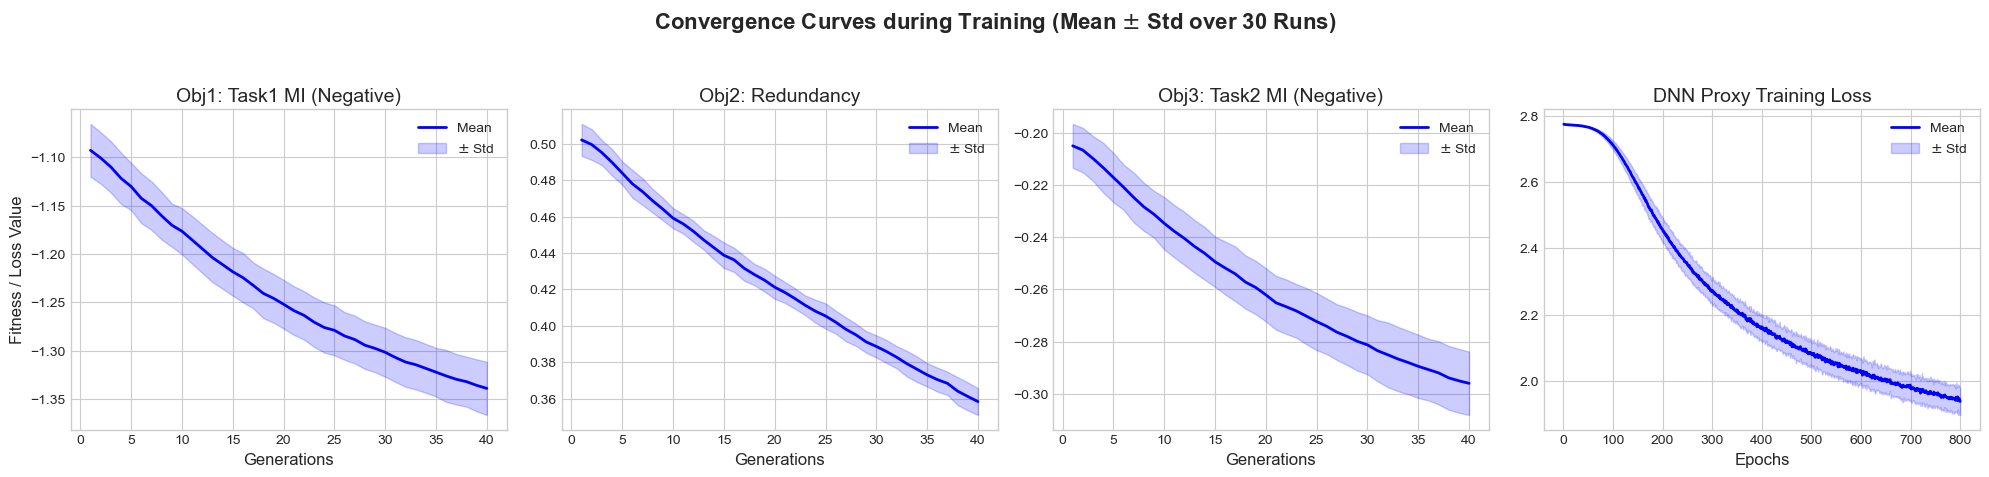

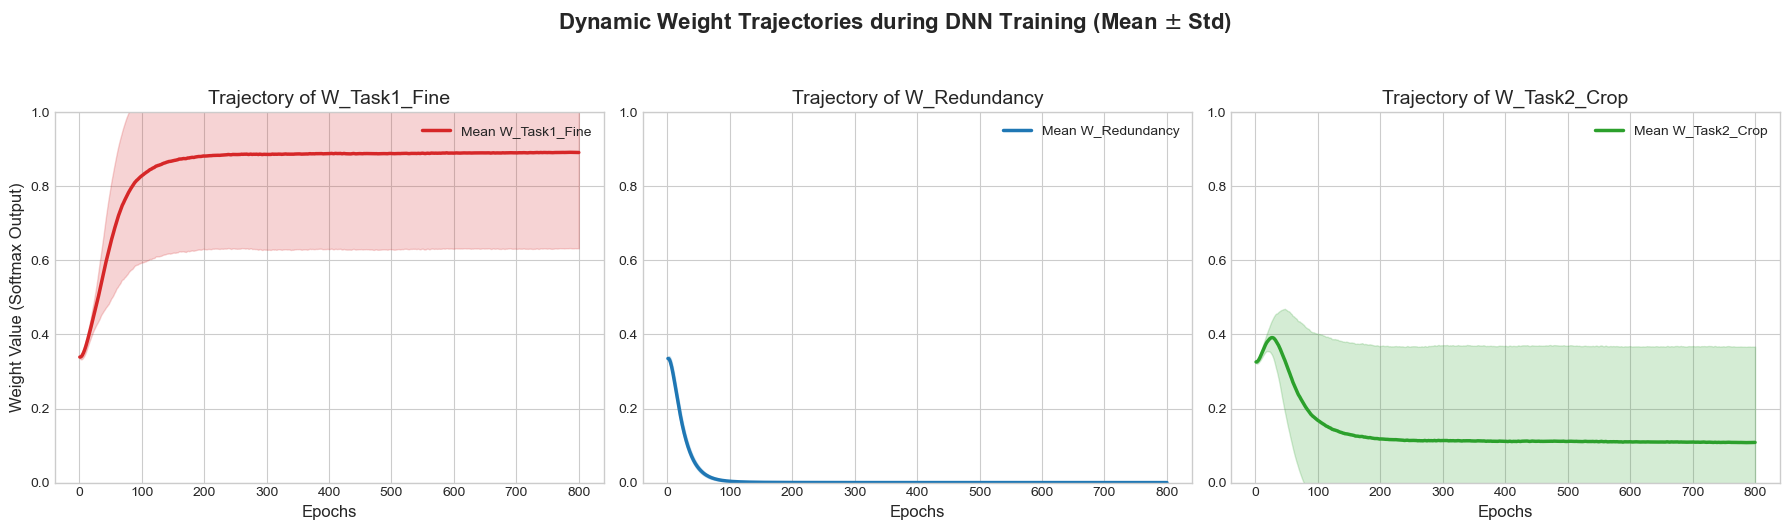

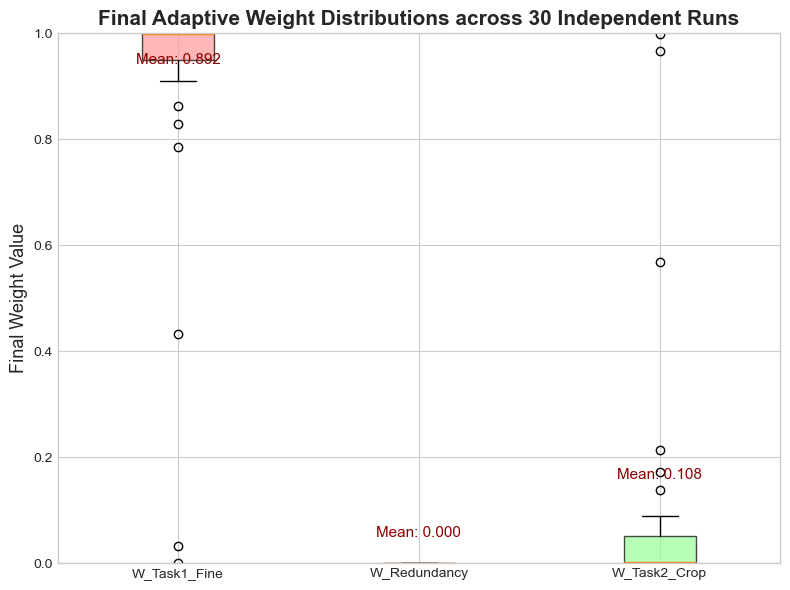

In [5]:
# ==============================================================
# 专属验证实验：Indian Pines Dataset (Hierarchical: Fine vs Coarse/Crop)
# 包含：GA-NN (Adaptive) 30次运行 + 收敛曲线 + 权重分布 + 动态权重轨迹图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_indian_pines
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe
from core.networks import train_softmask_dnn_proxy_multi

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_ip(feat, y_fine, y_crop, num_classes_t1, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    xt_tr, xt_te, yt1_tr, yt1_te, yt2_tr, yt2_te = train_test_split(
        feat, y_fine, y_crop, test_size=0.3, stratify=y_fine, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_task1 = mutual_info_classif(xt_tr, yt1_tr, random_state=current_seed)
    mi_task2 = mutual_info_classif(xt_tr, yt2_tr, random_state=current_seed)
    
    opts = {
        'xt_in': xt_tr, 
        'mi_task1': mi_task1, 
        'mi_task2': mi_task2, 
        'N': 200, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task1'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task2'))
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 层次化多任务深度特征融合 (核心：导出 w_hist 记录权重变化)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy_multi(
        pop1, pop2, pop3, xt_tr, yt1_tr, xt_tr.shape[1], num_classes_t1, True, temp_scale=5.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证层次化分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Task 1: Fine-grained
        clf_lda.fit(xt_tr[:, idx], yt1_tr)
        acc_t1 = clf_lda.score(xt_te[:, idx], yt1_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task1_Fine", "Score": acc_t1, "Time_Seconds": elapsed_time
        })
        
        # Task 2: Coarse/Crop
        clf_lda.fit(xt_tr[:, idx], yt2_tr)
        acc_t2 = clf_lda.score(xt_te[:, idx], yt2_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task2_Crop", "Score": acc_t2, "Time_Seconds": elapsed_time
        })
            
    # 【改动点】打包返回结果时，加入 w_hist
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, task1_labels, task2_labels, args):
    le_t1 = LabelEncoder()
    y_fine_enc = le_t1.fit_transform(task1_labels)
    num_classes_t1 = len(le_t1.classes_)
    y_crop = np.asarray(task2_labels)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_ip(feat, y_fine_enc, y_crop, num_classes_t1, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    df_t1 = df[df["Task"] == "Task1_Fine"]
    if not df_t1.empty:
        tb_t1 = df_t1.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Task 1: Fine-grained Classification Accuracy")
        print(tb_t1)
        tb_t1.to_csv("Final_IP_Task1_Fine_Ours.csv")
    
    df_t2 = df[df["Task"] == "Task2_Crop"]
    if not df_t2.empty:
        tb_t2 = df_t2.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Task 2: Coarse-grained (Crop) Classification Accuracy")
        print(tb_t2)
        tb_t2.to_csv("Final_IP_Task2_Crop_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_IP_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表"""
    
    # 转换为 NumPy 数组以便计算均值和方差
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs)', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Task1 MI (Negative)', 'Obj2: Redundancy', 'Obj3: Task2 MI (Negative)', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 【新增】动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        # w_hist_arr 形状为 (30次运行, Epochs, 3个权重)
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("IndianPines_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_fine, y_crop = load_indian_pines()
        run_benchmark(X, y_fine, y_crop, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        y_fine_mock = np.random.randint(0, 16, 150) 
        y_crop_mock = np.random.randint(0, 2, 150)  
        run_benchmark(X_mock, y_fine_mock, y_crop_mock, args)

Loading Data...
Loading Indian Pines Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information

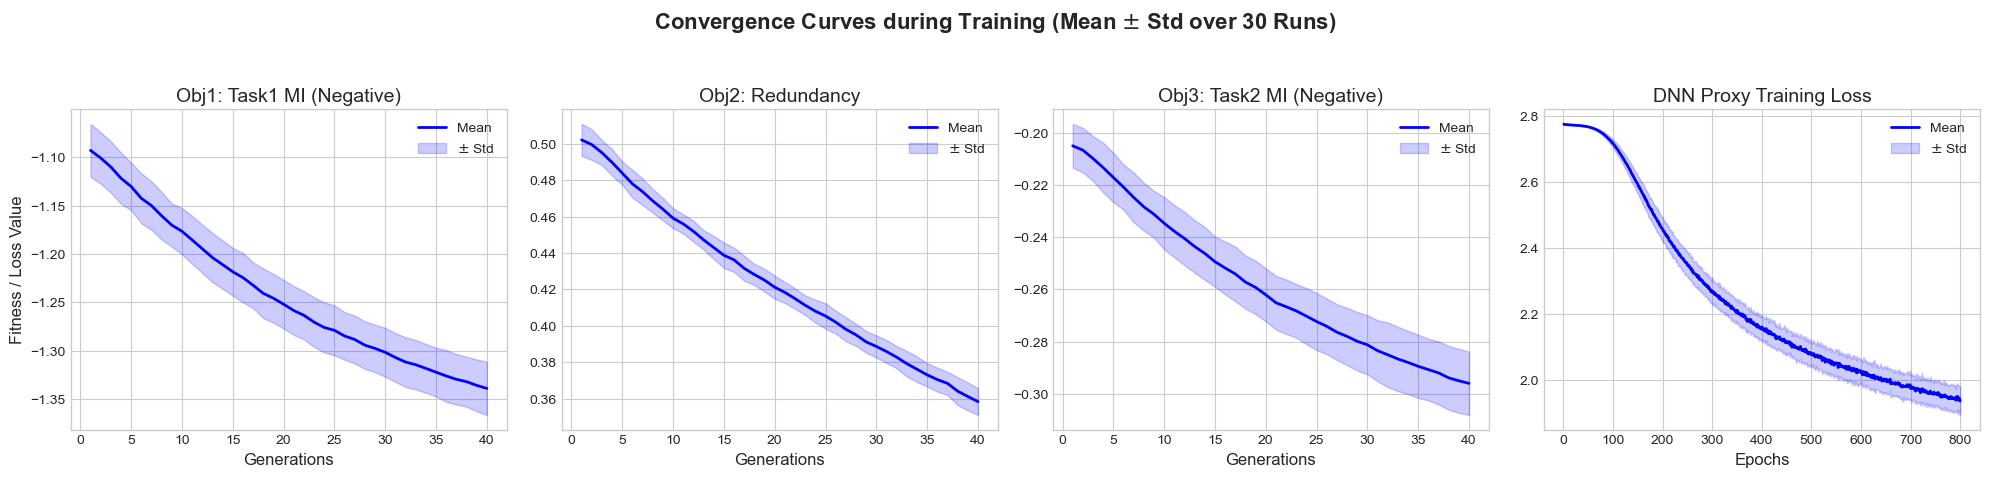

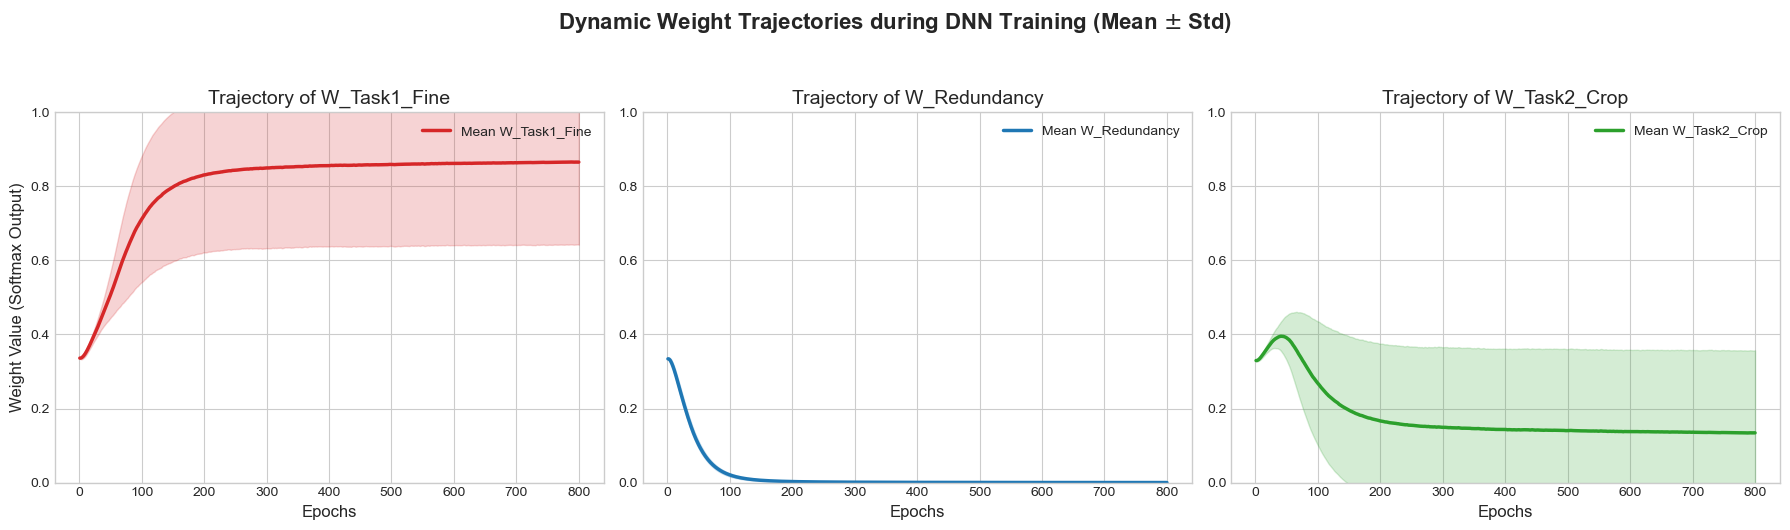

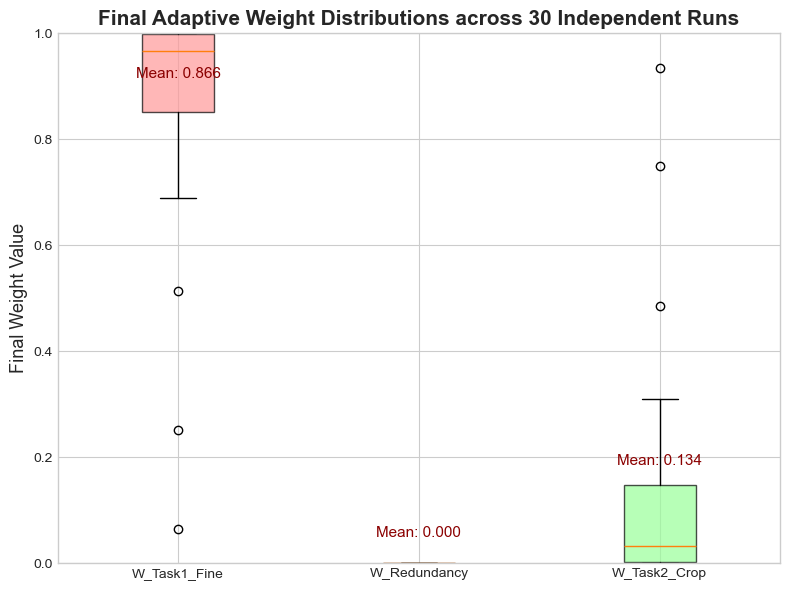

In [6]:
# ==============================================================
# 专属验证实验：Indian Pines Dataset (Hierarchical: Fine vs Coarse/Crop)
# 包含：GA-NN (Adaptive) 30次运行 + 收敛曲线 + 权重分布 + 动态权重轨迹图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_indian_pines
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe
from core.networks import train_softmask_dnn_proxy_multi

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_ip(feat, y_fine, y_crop, num_classes_t1, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    xt_tr, xt_te, yt1_tr, yt1_te, yt2_tr, yt2_te = train_test_split(
        feat, y_fine, y_crop, test_size=0.3, stratify=y_fine, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_task1 = mutual_info_classif(xt_tr, yt1_tr, random_state=current_seed)
    mi_task2 = mutual_info_classif(xt_tr, yt2_tr, random_state=current_seed)
    
    opts = {
        'xt_in': xt_tr, 
        'mi_task1': mi_task1, 
        'mi_task2': mi_task2, 
        'N': 200, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task1'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task2'))
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 层次化多任务深度特征融合 (核心：导出 w_hist 记录权重变化)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy_multi(
        pop1, pop2, pop3, xt_tr, yt1_tr, xt_tr.shape[1], num_classes_t1, True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证层次化分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Task 1: Fine-grained
        clf_lda.fit(xt_tr[:, idx], yt1_tr)
        acc_t1 = clf_lda.score(xt_te[:, idx], yt1_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task1_Fine", "Score": acc_t1, "Time_Seconds": elapsed_time
        })
        
        # Task 2: Coarse/Crop
        clf_lda.fit(xt_tr[:, idx], yt2_tr)
        acc_t2 = clf_lda.score(xt_te[:, idx], yt2_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task2_Crop", "Score": acc_t2, "Time_Seconds": elapsed_time
        })
            
    # 【改动点】打包返回结果时，加入 w_hist
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, task1_labels, task2_labels, args):
    le_t1 = LabelEncoder()
    y_fine_enc = le_t1.fit_transform(task1_labels)
    num_classes_t1 = len(le_t1.classes_)
    y_crop = np.asarray(task2_labels)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_ip(feat, y_fine_enc, y_crop, num_classes_t1, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    df_t1 = df[df["Task"] == "Task1_Fine"]
    if not df_t1.empty:
        tb_t1 = df_t1.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Task 1: Fine-grained Classification Accuracy")
        print(tb_t1)
        tb_t1.to_csv("Final_IP_Task1_Fine_Ours.csv")
    
    df_t2 = df[df["Task"] == "Task2_Crop"]
    if not df_t2.empty:
        tb_t2 = df_t2.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Task 2: Coarse-grained (Crop) Classification Accuracy")
        print(tb_t2)
        tb_t2.to_csv("Final_IP_Task2_Crop_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_IP_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表"""
    
    # 转换为 NumPy 数组以便计算均值和方差
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs)', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Task1 MI (Negative)', 'Obj2: Redundancy', 'Obj3: Task2 MI (Negative)', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 【新增】动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        # w_hist_arr 形状为 (30次运行, Epochs, 3个权重)
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("IndianPines_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_fine, y_crop = load_indian_pines()
        run_benchmark(X, y_fine, y_crop, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        y_fine_mock = np.random.randint(0, 16, 150) 
        y_crop_mock = np.random.randint(0, 2, 150)  
        run_benchmark(X_mock, y_fine_mock, y_crop_mock, args)

Loading Data...
Loading Indian Pines Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information

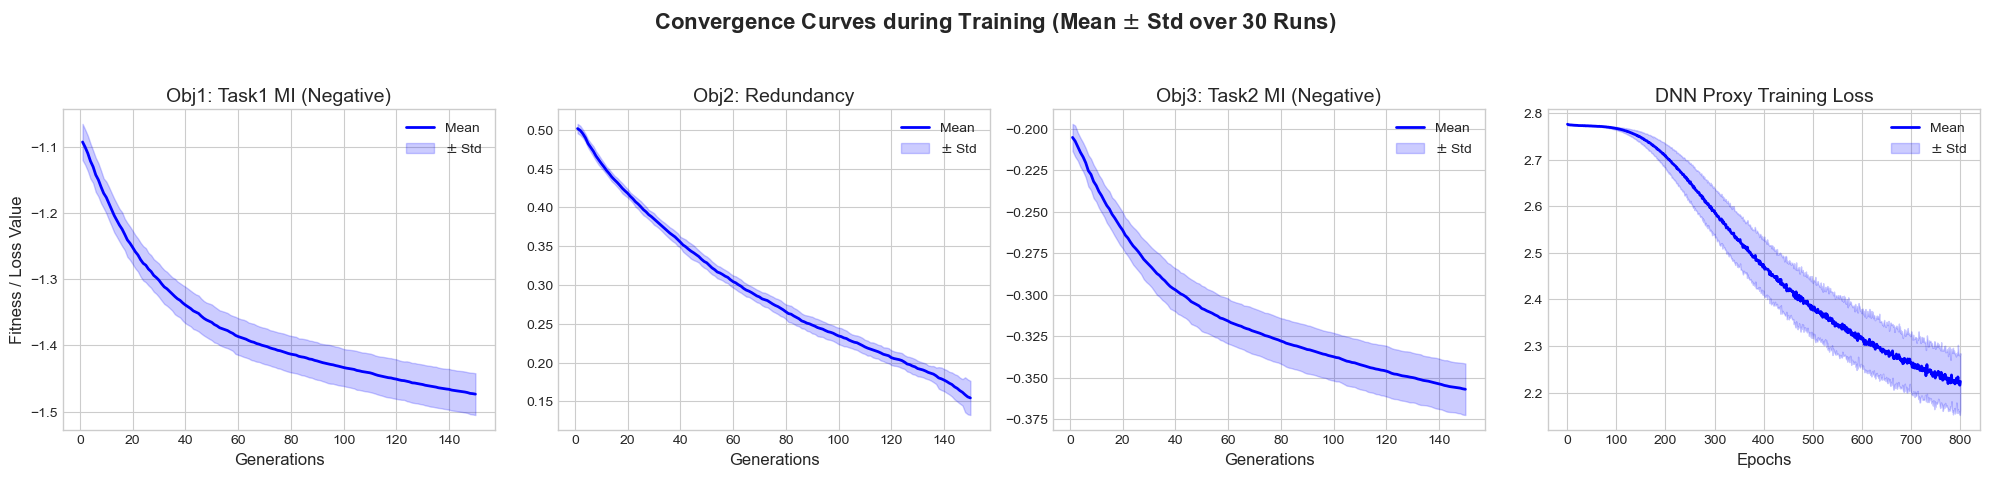

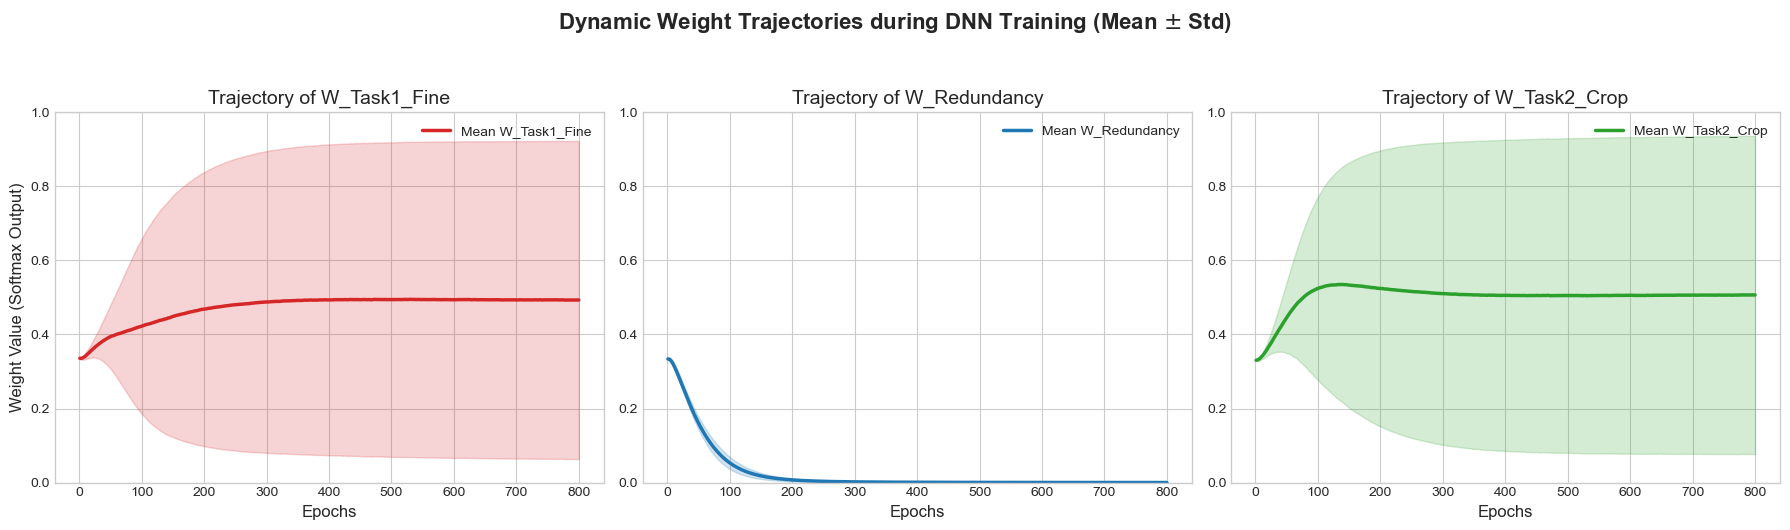

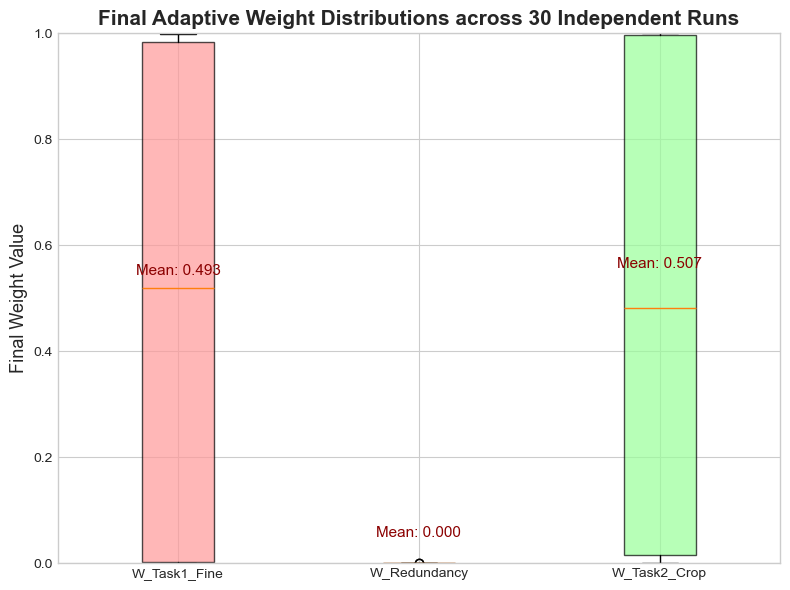

In [7]:
# ==============================================================
# 专属验证实验：Indian Pines Dataset (Hierarchical: Fine vs Coarse/Crop)
# 包含：GA-NN (Adaptive) 30次运行 + 收敛曲线 + 权重分布 + 动态权重轨迹图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_indian_pines
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe
from core.networks import train_softmask_dnn_proxy_multi

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_ip(feat, y_fine, y_crop, num_classes_t1, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    xt_tr, xt_te, yt1_tr, yt1_te, yt2_tr, yt2_te = train_test_split(
        feat, y_fine, y_crop, test_size=0.3, stratify=y_fine, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_task1 = mutual_info_classif(xt_tr, yt1_tr, random_state=current_seed)
    mi_task2 = mutual_info_classif(xt_tr, yt2_tr, random_state=current_seed)
    
    opts = {
        'xt_in': xt_tr, 
        'mi_task1': mi_task1, 
        'mi_task2': mi_task2, 
        'N': 200, 
        'T': 150, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task1'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task2'))
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 层次化多任务深度特征融合 (核心：导出 w_hist 记录权重变化)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy_multi(
        pop1, pop2, pop3, xt_tr, yt1_tr, xt_tr.shape[1], num_classes_t1, True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证层次化分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Task 1: Fine-grained
        clf_lda.fit(xt_tr[:, idx], yt1_tr)
        acc_t1 = clf_lda.score(xt_te[:, idx], yt1_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task1_Fine", "Score": acc_t1, "Time_Seconds": elapsed_time
        })
        
        # Task 2: Coarse/Crop
        clf_lda.fit(xt_tr[:, idx], yt2_tr)
        acc_t2 = clf_lda.score(xt_te[:, idx], yt2_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task2_Crop", "Score": acc_t2, "Time_Seconds": elapsed_time
        })
            
    # 【改动点】打包返回结果时，加入 w_hist
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, task1_labels, task2_labels, args):
    le_t1 = LabelEncoder()
    y_fine_enc = le_t1.fit_transform(task1_labels)
    num_classes_t1 = len(le_t1.classes_)
    y_crop = np.asarray(task2_labels)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_ip(feat, y_fine_enc, y_crop, num_classes_t1, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    df_t1 = df[df["Task"] == "Task1_Fine"]
    if not df_t1.empty:
        tb_t1 = df_t1.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Task 1: Fine-grained Classification Accuracy")
        print(tb_t1)
        tb_t1.to_csv("Final_IP_Task1_Fine_Ours.csv")
    
    df_t2 = df[df["Task"] == "Task2_Crop"]
    if not df_t2.empty:
        tb_t2 = df_t2.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Task 2: Coarse-grained (Crop) Classification Accuracy")
        print(tb_t2)
        tb_t2.to_csv("Final_IP_Task2_Crop_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_IP_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表"""
    
    # 转换为 NumPy 数组以便计算均值和方差
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs)', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Task1 MI (Negative)', 'Obj2: Redundancy', 'Obj3: Task2 MI (Negative)', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 【新增】动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        # w_hist_arr 形状为 (30次运行, Epochs, 3个权重)
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("IndianPines_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_fine, y_crop = load_indian_pines()
        run_benchmark(X, y_fine, y_crop, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        y_fine_mock = np.random.randint(0, 16, 150) 
        y_crop_mock = np.random.randint(0, 2, 150)  
        run_benchmark(X_mock, y_fine_mock, y_crop_mock, args)

Loading Data...
Loading Indian Pines Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information

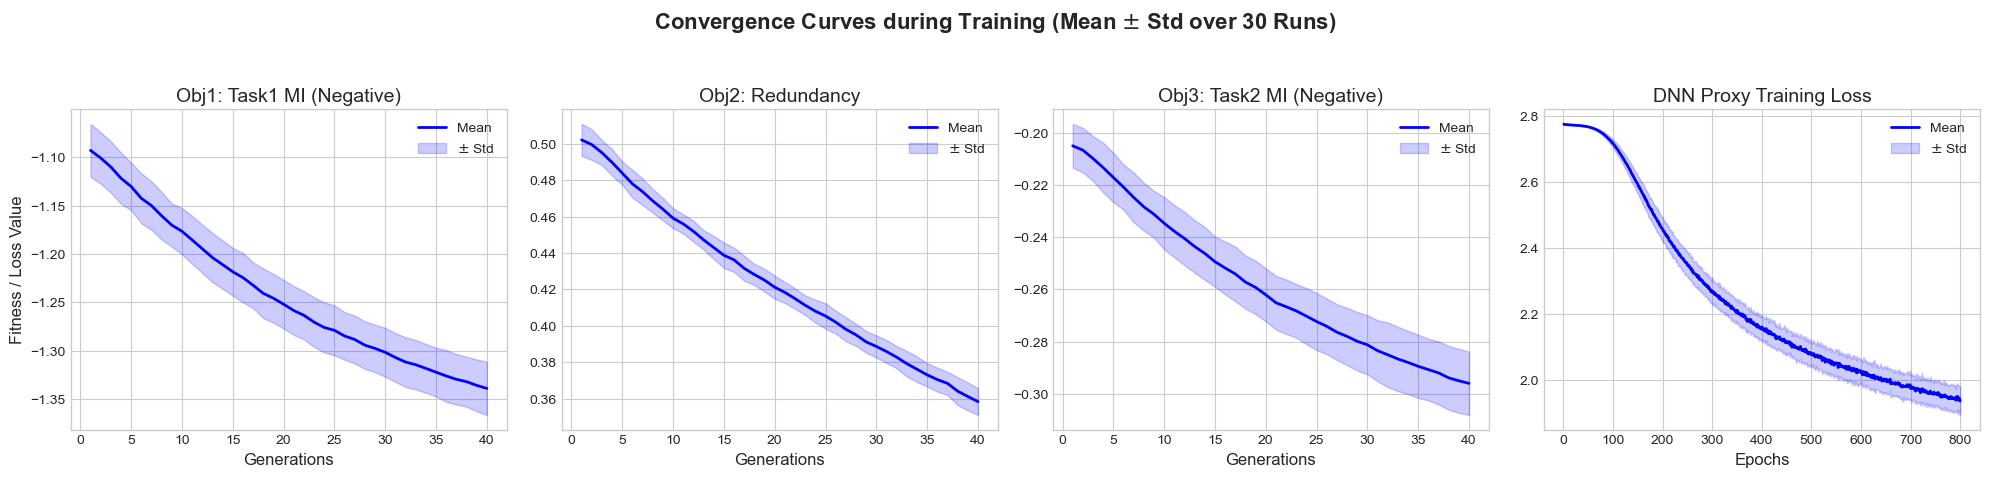

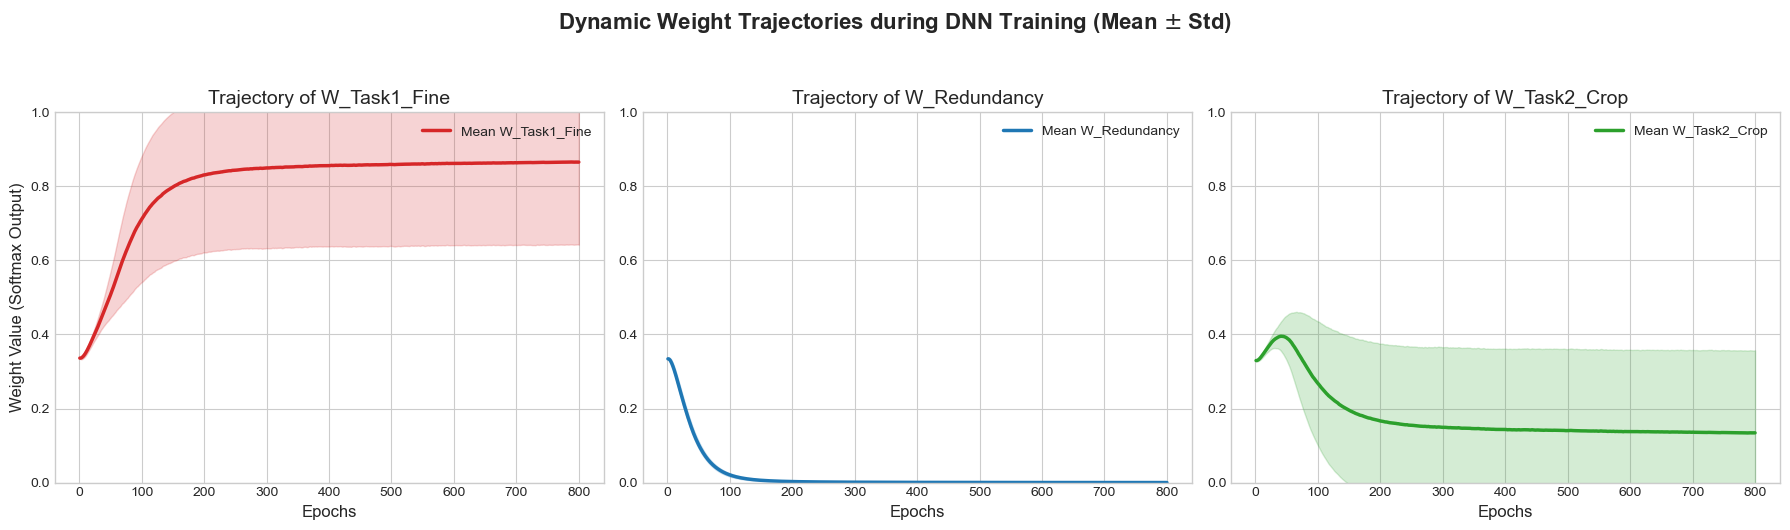

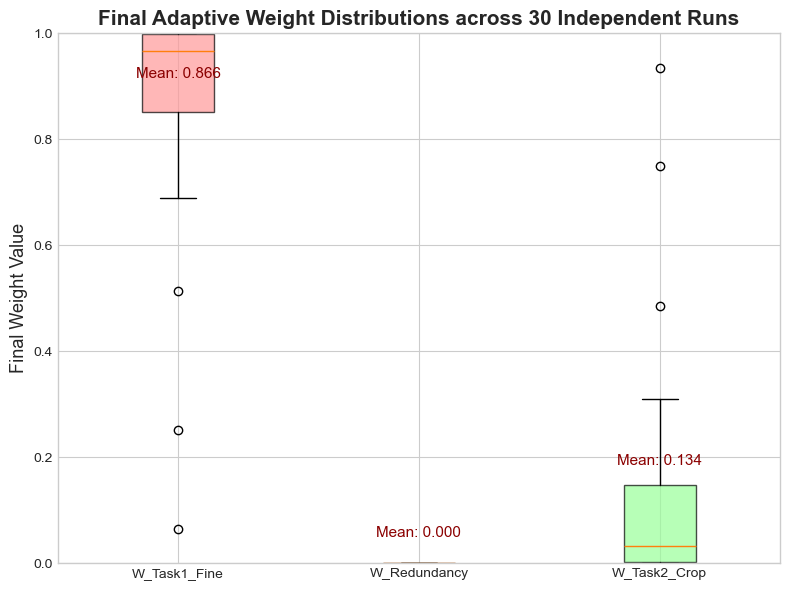

In [9]:
# ==============================================================
# 专属验证实验：Indian Pines Dataset (Hierarchical: Fine vs Coarse/Crop)
# 包含：GA-NN (Adaptive) 30次运行 + 收敛曲线 + 权重分布 + 动态权重轨迹图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_indian_pines
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe
from core.networks import train_softmask_dnn_proxy_multi

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_ip(feat, y_fine, y_crop, num_classes_t1, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    xt_tr, xt_te, yt1_tr, yt1_te, yt2_tr, yt2_te = train_test_split(
        feat, y_fine, y_crop, test_size=0.3, stratify=y_fine, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_task1 = mutual_info_classif(xt_tr, yt1_tr, random_state=current_seed)
    mi_task2 = mutual_info_classif(xt_tr, yt2_tr, random_state=current_seed)
    
    opts = {
        'xt_in': xt_tr, 
        'mi_task1': mi_task1, 
        'mi_task2': mi_task2, 
        'N': 200, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task1'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task2'))
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 层次化多任务深度特征融合 (核心：导出 w_hist 记录权重变化)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy_multi(
        pop1, pop2, pop3, xt_tr, yt1_tr, xt_tr.shape[1], num_classes_t1, True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证层次化分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Task 1: Fine-grained
        clf_lda.fit(xt_tr[:, idx], yt1_tr)
        acc_t1 = clf_lda.score(xt_te[:, idx], yt1_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task1_Fine", "Score": acc_t1, "Time_Seconds": elapsed_time
        })
        
        # Task 2: Coarse/Crop
        clf_lda.fit(xt_tr[:, idx], yt2_tr)
        acc_t2 = clf_lda.score(xt_te[:, idx], yt2_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task2_Crop", "Score": acc_t2, "Time_Seconds": elapsed_time
        })
            
    # 【改动点】打包返回结果时，加入 w_hist
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, task1_labels, task2_labels, args):
    le_t1 = LabelEncoder()
    y_fine_enc = le_t1.fit_transform(task1_labels)
    num_classes_t1 = len(le_t1.classes_)
    y_crop = np.asarray(task2_labels)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_ip(feat, y_fine_enc, y_crop, num_classes_t1, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    df_t1 = df[df["Task"] == "Task1_Fine"]
    if not df_t1.empty:
        tb_t1 = df_t1.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Task 1: Fine-grained Classification Accuracy")
        print(tb_t1)
        tb_t1.to_csv("Final_IP_Task1_Fine_Ours.csv")
    
    df_t2 = df[df["Task"] == "Task2_Crop"]
    if not df_t2.empty:
        tb_t2 = df_t2.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Task 2: Coarse-grained (Crop) Classification Accuracy")
        print(tb_t2)
        tb_t2.to_csv("Final_IP_Task2_Crop_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_IP_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表"""
    
    # 转换为 NumPy 数组以便计算均值和方差
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs)', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Task1 MI (Negative)', 'Obj2: Redundancy', 'Obj3: Task2 MI (Negative)', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 【新增】动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        # w_hist_arr 形状为 (30次运行, Epochs, 3个权重)
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("IndianPines_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_fine, y_crop = load_indian_pines()
        run_benchmark(X, y_fine, y_crop, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        y_fine_mock = np.random.randint(0, 16, 150) 
        y_crop_mock = np.random.randint(0, 2, 150)  
        run_benchmark(X_mock, y_fine_mock, y_crop_mock, args)

Loading Data...
Loading Indian Pines Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information

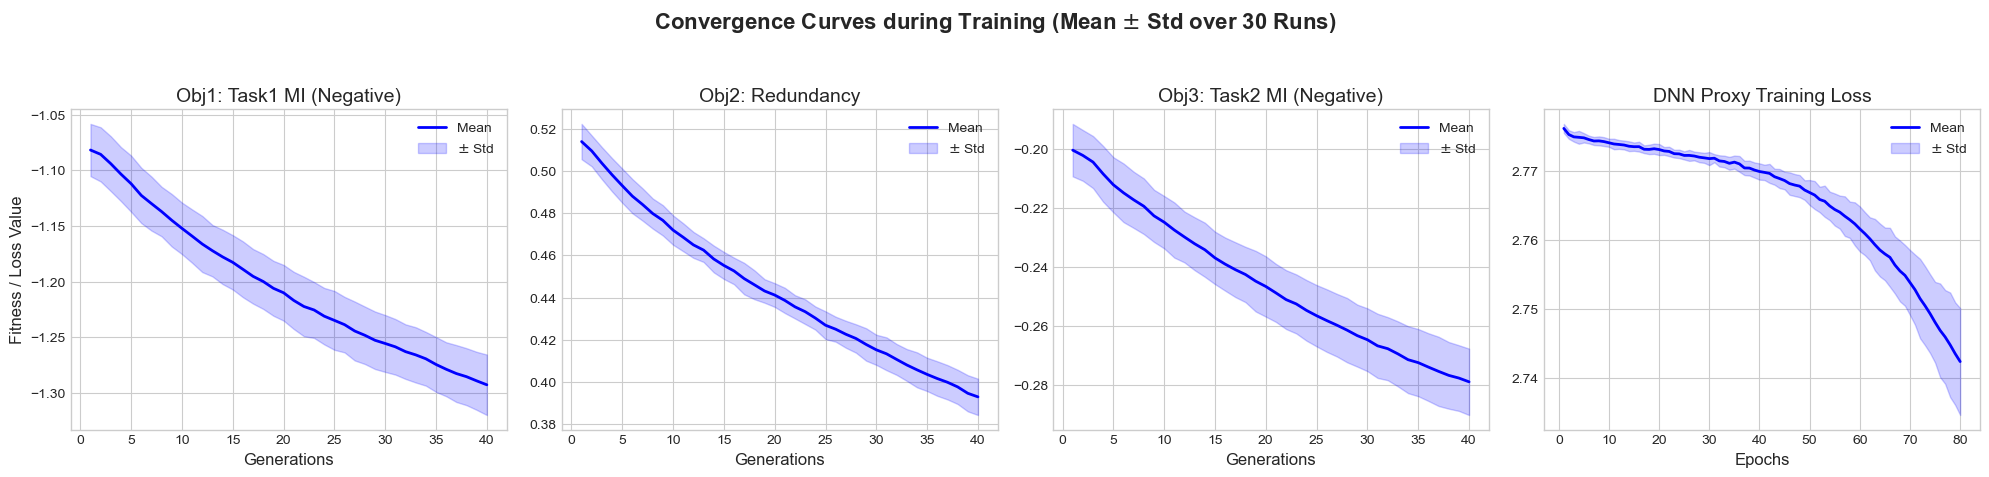

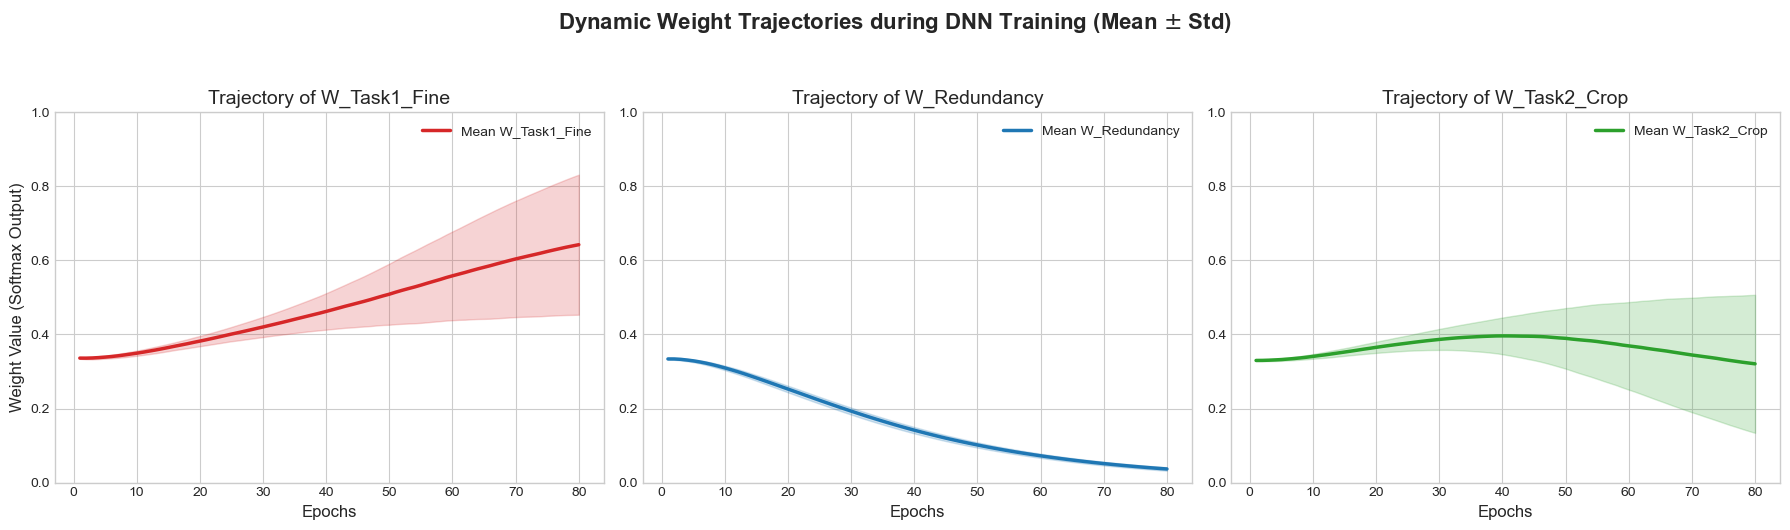

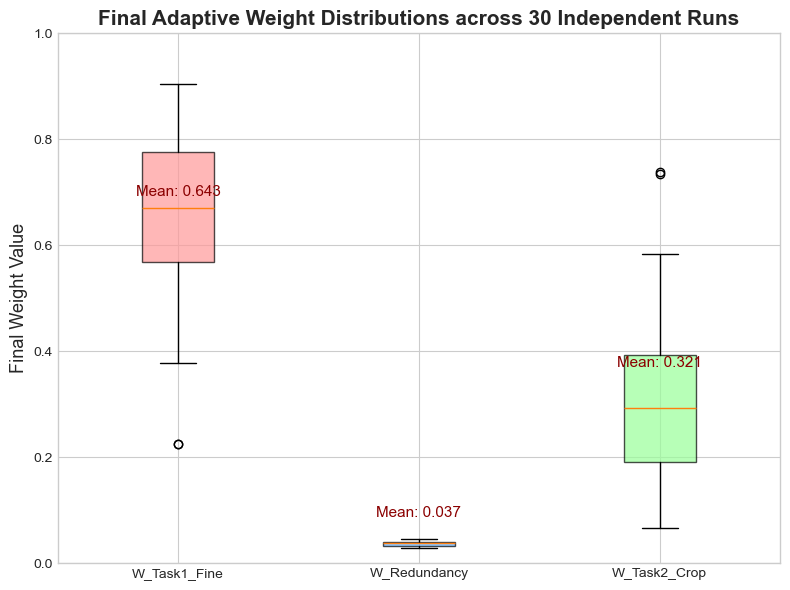

In [1]:
# ==============================================================
# 专属验证实验：Indian Pines Dataset (Hierarchical: Fine vs Coarse/Crop)
# 包含：GA-NN (Adaptive) 30次运行 + 收敛曲线 + 权重分布 + 动态权重轨迹图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_indian_pines
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe
from core.networks import train_softmask_dnn_proxy_multi

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_ip(feat, y_fine, y_crop, num_classes_t1, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    xt_tr, xt_te, yt1_tr, yt1_te, yt2_tr, yt2_te = train_test_split(
        feat, y_fine, y_crop, test_size=0.3, stratify=y_fine, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_task1 = mutual_info_classif(xt_tr, yt1_tr, random_state=current_seed)
    mi_task2 = mutual_info_classif(xt_tr, yt2_tr, random_state=current_seed)
    
    opts = {
        'xt_in': xt_tr, 
        'mi_task1': mi_task1, 
        'mi_task2': mi_task2, 
        'N': 40, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task1'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_task2'))
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 层次化多任务深度特征融合 (核心：导出 w_hist 记录权重变化)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy_multi(
        pop1, pop2, pop3, xt_tr, yt1_tr, xt_tr.shape[1], num_classes_t1, True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证层次化分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Task 1: Fine-grained
        clf_lda.fit(xt_tr[:, idx], yt1_tr)
        acc_t1 = clf_lda.score(xt_te[:, idx], yt1_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task1_Fine", "Score": acc_t1, "Time_Seconds": elapsed_time
        })
        
        # Task 2: Coarse/Crop
        clf_lda.fit(xt_tr[:, idx], yt2_tr)
        acc_t2 = clf_lda.score(xt_te[:, idx], yt2_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Task2_Crop", "Score": acc_t2, "Time_Seconds": elapsed_time
        })
            
    # 【改动点】打包返回结果时，加入 w_hist
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, task1_labels, task2_labels, args):
    le_t1 = LabelEncoder()
    y_fine_enc = le_t1.fit_transform(task1_labels)
    num_classes_t1 = len(le_t1.classes_)
    y_crop = np.asarray(task2_labels)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Indian Pines): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_ip(feat, y_fine_enc, y_crop, num_classes_t1, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    df_t1 = df[df["Task"] == "Task1_Fine"]
    if not df_t1.empty:
        tb_t1 = df_t1.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Task 1: Fine-grained Classification Accuracy")
        print(tb_t1)
        tb_t1.to_csv("Final_IP_Task1_Fine_Ours.csv")
    
    df_t2 = df[df["Task"] == "Task2_Crop"]
    if not df_t2.empty:
        tb_t2 = df_t2.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Task 2: Coarse-grained (Crop) Classification Accuracy")
        print(tb_t2)
        tb_t2.to_csv("Final_IP_Task2_Crop_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_IP_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表"""
    
    # 转换为 NumPy 数组以便计算均值和方差
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs)', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Task1 MI (Negative)', 'Obj2: Redundancy', 'Obj3: Task2 MI (Negative)', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 【新增】动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        # w_hist_arr 形状为 (30次运行, Epochs, 3个权重)
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("IndianPines_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Task1_Fine', 'W_Redundancy', 'W_Task2_Crop'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("IndianPines_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_fine, y_crop = load_indian_pines()
        run_benchmark(X, y_fine, y_crop, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        y_fine_mock = np.random.randint(0, 16, 150) 
        y_crop_mock = np.random.randint(0, 2, 150)  
        run_benchmark(X_mock, y_fine_mock, y_crop_mock, args)